# Ethos before and after single-domain unlearning
Six models each have eight independently trained checkpoints: four StereoSet domains in English and four in Ukrainian. Every checkpoint has eight paired Fair-UK evaluations. Each effect compares the original model with one Ethos checkpoint on identical items in one evaluation language.

The tables show target mitigation, changes in other domains, language transfer and language-modeling score (LMS). The external benchmarks use their own bias and accuracy measures. Restart the kernel and run all cells to generate the CSV tables and both heatmaps. The [study instructions](../README.md#reproduce-the-seed-42-analysis) describe the environment and input archive.

In [1]:
import os
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

study_path = Path("redistibution-artifacts/ethos-stereoset")
candidates = [
    Path(os.environ.get("ETHOS_ARTIFACT_ROOT", ".")).resolve(),
    Path.cwd(),
    *Path.cwd().parents,
]
study = next(
    (
        path
        for parent in candidates
        for path in (parent, parent / study_path)
        if (path / "analysis/ethos_redistribution.ipynb").is_file()
    ),
    None,
)
if study is None:
    raise FileNotFoundError("Set ETHOS_ARTIFACT_ROOT to the ethos-stereoset directory")
sys.path.insert(0, str(study / "ethos"))

In [2]:
from redistribution import (
    KEY,
    TOLERANCE,
    bbq_categories,
    external_rows,
    load_reports,
    stereoset_rows,
    summarize_bbq_categories,
)
from suite_data import read

spec = read(study / "config/stereoset_domains.json")
reports = load_reports(study)
domains = list(spec["domains"])
labels = {"race": "race/ethnicity"}
model_names = {r["cell"]["model"]: r["model_label"] for r in reports}
models = [model_names[m] for m in spec["models"]]
languages = ["en", "uk"]
routes = list(product(languages, repeat=2))
out = study / "analysis/outputs"
out.mkdir(parents=True, exist_ok=True)

sources = pd.DataFrame(
    [
        {
            **r["cell"],
            **{
                k: r[k]
                for k in (
                    "task",
                    "evaluation_language",
                    "job",
                    "rows",
                    "pair",
                    "receipt_sha256",
                    "paired_sha256",
                    "training_sha256",
                    "dataset_sha256",
                    "source_rows_sha256",
                    "evaluator_revision",
                )
            },
        }
        for r in reports
    ]
)
display(
    sources.groupby("task").agg(paired_evaluations=("job", "size"), rows_per_pair=("rows", "first"))
)

,paired_evaluations,rows_per_pair
task,,
bbq_en,48,58492
bbq_uk,48,58492
stereoset_en,48,949
stereoset_uk,48,949
winobias_en_controlled,48,1580
winobias_en_natural,48,558
winobias_uk_controlled,48,1580
winobias_uk_natural,48,1674


## Analyst checklist for the 18 FairForget metrics

Each checkpoint forgot one StereoSet bias domain (gender, profession, race/ethnicity or religion) in English or Ukrainian. All 48 checkpoints were evaluated in both languages. The four domains support target-to-other-domain comparisons and cross-language comparisons.

Eight sheet rows have results in this study. Seven use StereoSet and its experiment records. Row 17 uses the previously collected BBQ evaluations. For the other ten rows, the checklist distinguishes what the existing benchmarks can measure from what requires a different intervention or annotations. The [JUPITER follow-up](utility_refusal/README.md) covers Belebele and Global-MMLU accuracy and free-text generation on the original BBQ questions in both languages. The [dispatch record](utility_refusal/dispatch.json) tracks those runs. The original BBQ scores supply the forced-choice abstention diagnostic.

Sheet rows 2–19 retain their original numbering. Each checked row links its results to a CSV generated in `analysis/outputs/`. The results cover one training seed. [FairForget metric sheet](https://docs.google.com/spreadsheets/d/1FJGHttlJan3xpSjxHPOqYuJBsf27_LU-Uzu09j2dIVk/edit?gid=0#gid=0) · [Machine-readable checklist](metric_checklist.csv)

In [3]:
checklist = pd.read_csv(study / "analysis/metric_checklist.csv", keep_default_na=False)
if checklist.sheet_row.tolist() != list(range(2, 20)) or not checklist.metric_id.is_unique:
    raise ValueError("Expected one checklist entry per FairForget sheet row")
marks = {
    "Reportable": "☑",
    "Unavailable with StereoSet": "☐",
    "Follow-up submitted": "☐",
    "BBQ abstention available": "◐",
}
lines = ["| Sheet row | Metric | Status | Result or evidence needed |", "|---:|---|---|---|"]
for item in checklist.itertuples():
    evidence = item.evidence_or_gap
    if item.result_file:
        evidence += f" See `{item.result_file}`."
    lines.append(
        f"| {item.sheet_row} | {item.metric} | {marks[item.status]} {item.status} | {evidence} |"
    )
display(Markdown("\n".join(lines)))

| Sheet row | Metric | Status | Result or evidence needed |
|---:|---|---|---|
| 2 | Forget efficacy | ☑ Reportable | Target StereoSet distance from 50 before and after. Efficacy is before minus after, so positive values mean improvement. See `target_and_off_target.csv`. |
| 3 | Net neutralization rate (NNR) | ☑ Reportable | Family-weighted net neutralization on baseline-eligible target items. The model- and language-specific empirical band uses two unchanged-base development runs. Sensitivity at the 10th and 30th percentiles accompanies the primary 20th percentile. See `checkpoint_nnr_ri.csv`. |
| 4 | Retain utility | ☐ Follow-up submitted | The bilingual Belebele and Global-MMLU follow-up compares base and checkpoint accuracy on the same questions. General retain utility has two benchmark endpoints. Group-specific retain utility remains separate. See utility_refusal/dispatch.json for collection status. |
| 5 | Language-modeling score (LMS) | ☑ Reportable | Native target-macro LMS on the same held-out triplets measures preference for meaningful text over the unrelated control. See `stereoset_domains.csv`. |
| 6 | ICAT | ☑ Reportable | Native before/after ICAT uses SS and LMS from the same held-out domain with the same target weighting. See `stereoset_domains.csv`. |
| 7 | M1 · Worst-group quality | ☐ Unavailable with StereoSet | The release has no common retain questions and reference answers across matched actor, gender and age groups. The four bias domains are different sets of items. |
| 8 | M1b · Minimum-to-maximum quality ratio | ☐ Unavailable with StereoSet | The minimum and maximum must come from the eligible matched groups in M1. StereoSet supplies neither group quality endpoint. |
| 9 | M2 · Disparity in quality loss | ☐ Unavailable with StereoSet | A range or standard deviation of group quality losses requires the same retain questions before and after for every eligible group. StereoSet measures sentence preferences. |
| 10 | M3a · Actor-to-actor redistribution | ☐ Unavailable with StereoSet | Each checkpoint forgot a whole domain. M3a requires separate actor-only interventions in both directions and the same claims matched across actors. |
| 11 | M3b · Within-actor topic redistribution | ☐ Unavailable with StereoSet | Each checkpoint forgot a whole domain. M3b requires forgetting one topic within one actor and comparing that actor’s matched near and far topics. |
| 12 | M3c · Within-claim demographic redistribution | ☐ Unavailable with StereoSet | The intervention included the whole domain. M3c requires forgetting only a claim’s demographically unspecified version and scoring matched gender and age variants of that claim. |
| 13 | M3d · Cross-language redistribution | ☑ Reportable | Compare the same checkpoint and held-out StereoSet domain in both languages. Keep language-specific base scores, signed SS changes and distance-from-parity changes. See `cross_language.csv`. |
| 14 | Redistribution Index (RI) | ☑ Reportable | Domain RI averages positive harm increases across all three other domains. Each checkpoint and evaluation language has a denominator stability test and an explicit status. Language RI uses the untrained language as its separate recipient axis. See `checkpoint_nnr_ri.csv`. |
| 15 | M4a · Over-refusal on benign requests | ☐ Follow-up submitted | The free-text BBQ follow-up collects unconstrained replies on the original questions in both languages. Explicit refusals and insufficient-evidence answers have separate review labels. Final M4a rates require response-level scoring. See utility_refusal/dispatch.json. |
| 16 | M4b · Over-abstention with sufficient evidence | ◐ BBQ abstention available | The saved BBQ unknown-option rates cover all 48 checkpoints in EN and UK by ambiguity condition and category. Unknown on answerable items measures forced-choice over-abstention. The pooled and category results do not supply the full favorable/adverse factual breakdown in the sheet. See bbq_unknown_rates.csv. |
| 17 | BBQ bias by group | ☑ Reportable | Use the signed native bias score in each BBQ category, with eligible counts and availability. Ambiguous items are the sheet endpoint. Disambiguated items are a separate diagnostic. See `bbq_categories.csv`. |
| 18 | Training imbalance as a covariate | ☑ Reportable | Within each trained StereoSet domain, correlate named-target training exposure with the change in held-out bias distance. Report both native streams, group counts and ties. Constant ranks have no correlation. See `training_imbalance.csv`. |
| 19 | Severity slice | ☐ Unavailable with StereoSet | The release has no source-bound severity ratings for its held-out claims. The bias-domain and sentence-role labels carry no severity value. |

### Rows 3 and 14 · Development calibration and paired effects

The frozen development release contains 41 English–Ukrainian item pairs from 40 semantic families. Two fresh runs of each unchanged model supply native stereotype-minus-antistereotype margins for each language. The empirical neutrality band uses the 20th percentile of absolute margins in the first run and the maximum between-run margin difference as a floor. It measures weak preference at this development calibration. The development examples are ordinary StereoSet triplets. A human judgment of neutrality would require separate labels.

For domain RI, each of the three other domains receives one-third weight. The numerator averages their positive increases in distance from SS = 50. The denominator is the target reduction. It must exceed the larger of one percentage point and the observed no-update development shift for that domain. Its paired 95% lower bound must also exceed zero. Language RI uses one recipient, the other evaluation language on the trained domain, with unit weight. Rules were fixed for this follow-up after the original seed-42 effects had been reported.

## StereoSet scoring
The native target-macro stereotype score (SS) gives each named target within a domain equal weight. An SS of 50 is parity. Bias magnitude is `abs(SS − 50)`. A positive change in magnitude means the preference strengthened, including cases that crossed 50. Negative means it weakened. LMS measures preference for meaningful text over an unrelated alternative. ICAT combines LMS and stereotype balance.

All languages and checkpoints use the same protected 949 StereoSet IDs. The protocol uses seed 42 and zero StereoSet bootstrap draws because some protected families span scoring strata. All domain and language contrasts below are descriptive. Numerical comparisons use full precision and a 1e−9 point tolerance for ties.

In [4]:
scores = stereoset_rows(reports, spec["domains"])
scores["distance_before"] = (scores.ss_before - 50).abs()
scores["distance_after"] = (scores.ss_after - 50).abs()
scores["bias_change"] = scores.distance_after - scores.distance_before
scores["ss_change"] = scores.ss_after - scores.ss_before
scores["lms_change"] = scores.lms_after - scores.lms_before
scores["icat_change"] = scores.icat_after - scores.icat_before
scores["target_reduced"] = scores.targeted & (scores.bias_change < -TOLERANCE)
scores["other_increased"] = ~scores.targeted & (scores.bias_change > TOLERANCE)
display(
    scores[["evaluated", "items", "named_targets"]]
    .drop_duplicates()
    .set_index("evaluated")
    .reindex(domains)
)

,items,named_targets
evaluated,,
gender,110,10
profession,354,30
race,453,36
religion,32,3


## Which checkpoints improved their target and worsened another domain?
A checkpoint contributes a separate observation in each evaluation language. Each observation has one target and three off-target comparisons. The count of simultaneous changes requires both effects on the same checkpoint and in the same evaluation language.

In [5]:
target = scores.loc[scores.targeted].copy()
target["forget_efficacy"] = target.distance_before - target.distance_after
off_target = scores.loc[~scores.targeted].copy()
increases = off_target.loc[off_target.other_increased].groupby(KEY).evaluated.agg(", ".join)
target = target.join(increases.rename("other_domains_worsened"), on=KEY)
target["has_off_target_increase"] = target.other_domains_worsened.notna()
target["other_domains_worsened"] = target.other_domains_worsened.fillna("—")
target["target_and_other"] = target.target_reduced & target.has_off_target_increase
target["lms_fell_with_target_bias"] = target.target_reduced & (target.lms_change < -TOLERANCE)
display(
    Markdown(
        f"**{target.target_reduced.sum()} of {len(target)}** target comparisons moved toward parity. "
        f"**{target.target_and_other.sum()}** of those also had an off-target increase. "
        f"Across all {len(off_target)} off-target comparisons, **{off_target.other_increased.sum()}** moved farther from parity. "
        f"Target LMS fell in **{target.lms_fell_with_target_bias.sum()}** of the {target.target_reduced.sum()} target improvements."
    )
)
summary = (
    target.groupby(["train", "eval"])
    .agg(
        comparisons=("target", "size"),
        target_reduced=("target_reduced", "sum"),
        target_reduced_and_other_increased=("target_and_other", "sum"),
        target_reduced_and_lms_fell=("lms_fell_with_target_bias", "sum"),
    )
    .join(
        off_target.groupby(["train", "eval"]).other_increased.sum().rename("off_target_increases")
    )
)
display(summary)
display(
    off_target.groupby("evaluated")
    .other_increased.agg(["sum", "size"])
    .rename(columns={"sum": "bias_increases", "size": "off_target_comparisons"})
    .reindex(domains)
)

**84 of 96** target comparisons moved toward parity. **30** of those also had an off-target increase. Across all 288 off-target comparisons, **43** moved farther from parity. Target LMS fell in **82** of the 84 target improvements.

comparisons  target_reduced  target_reduced_and_other_increased  \
train eval                                                                    
en    en             24              23                                   7   
      uk             24              20                                   7   
uk    en             24              22                                   6   
      uk             24              19                                  10   

            target_reduced_and_lms_fell  off_target_increases  
train eval                                                     
en    en                             21                     7  
      uk                             20                    10  
uk    en                             22                     7  
      uk                             19                    19

,bias_increases,off_target_comparisons
evaluated,,
gender,7,72
profession,4,72
race,11,72
religion,21,72


## Target bias before and after, including language transfer
Each cell below gives the held-out target domain’s distance from SS = 50 **before → after**. Smaller is closer to parity. The four columns represent four independently trained checkpoints. The final column counts increases among the 12 off-target observations for that model and language pair.

In [6]:
def before_after(before, after):
    return pd.Series(
        [f"{a:.1f} → {b:.1f}" for a, b in zip(before, after, strict=True)], index=before.index
    )


model_routes = ["model", "train", "eval"]
ordered_routes = pd.MultiIndex.from_product([models, languages, languages], names=model_routes)
target_table = (
    target.assign(distance=before_after(target.distance_before, target.distance_after))
    .pivot(index=model_routes, columns="target", values="distance")
    .reindex(index=ordered_routes, columns=domains)
    .rename(columns=labels)
)
off_counts = off_target.groupby(model_routes).other_increased.sum().rename("increased / 12")
display(target_table.join(off_counts))

gender   profession race/ethnicity  \
model                 train eval                                            
Llama 3.1 8B Instruct en    en    18.3 → 12.9   21.2 → 8.7     13.0 → 1.2   
                            uk      4.6 → 1.8    8.1 → 4.7      9.6 → 0.5   
                      uk    en    18.3 → 13.6   21.2 → 4.8     13.0 → 3.4   
                            uk      4.6 → 4.9    8.1 → 3.4      9.6 → 5.4   
Gemma 3 12B IT        en    en    21.3 → 14.7  21.9 → 11.0     15.4 → 3.3   
                            uk      7.7 → 1.7    8.6 → 8.8     11.1 → 4.9   
                      uk    en    21.3 → 19.6  21.9 → 13.1     15.4 → 6.0   
                            uk      7.7 → 4.1    8.6 → 3.3     11.1 → 1.6   
Qwen3 8B              en    en    20.0 → 12.6   14.4 → 7.6      2.7 → 2.5   
                            uk      7.2 → 6.0    4.6 → 3.2      7.9 → 6.6   
                      uk    en    20.0 → 15.3   14.4 → 9.8      2.7 → 2.9   
                            uk      7.2 → 9.4    4.6 → 3.1      7.9 → 4.4   
Lapa 12B              en    en    23.5 → 18.5   16.4 → 5.2     14.0 → 8.3   
                            uk    19.3 → 15.1    9.2 → 2.3     12.3 → 8.1   
                      uk    en     23.5 → 7.5   16.4 → 7.5     14.0 → 8.3   
                            uk    19.3 → 11.5    9.2 → 6.4     12.3 → 4.9   
Mamay 12B             en    en    22.9 → 17.8  18.4 → 11.4     17.1 → 4.6   
                            uk      7.1 → 2.0    9.4 → 8.6     12.2 → 7.2   
                      uk    en    22.9 → 17.8   18.4 → 9.6     17.1 → 4.9   
                            uk      7.1 → 2.1    9.4 → 4.8     12.2 → 5.9   
Mamay 27B             en    en    26.2 → 17.8   17.9 → 9.1     15.6 → 7.9   
                            uk      4.8 → 1.2   11.2 → 7.7    13.1 → 11.5   
                      uk    en    26.2 → 22.0  17.9 → 12.4     15.6 → 4.9   
                            uk      4.8 → 2.9   11.2 → 7.8     13.1 → 9.6   

                                     religion  increased / 12  
model                 train eval                               
Llama 3.1 8B Instruct en    en     17.0 → 4.4               0  
                            uk      5.6 → 2.2               2  
                      uk    en     17.0 → 2.8               1  
                            uk      5.6 → 3.7               3  
Gemma 3 12B IT        en    en     14.1 → 2.2               2  
                            uk      6.8 → 8.3               1  
                      uk    en     14.1 → 1.2               1  
                            uk     6.8 → 12.2               4  
Qwen3 8B              en    en      6.2 → 1.6               2  
                            uk      3.5 → 7.3               6  
                      uk    en      6.2 → 6.5               3  
                            uk     3.5 → 13.6               5  
Lapa 12B              en    en    11.1 → 17.8               3  
                            uk    21.3 → 16.2               0  
                      uk    en     11.1 → 6.0               1  
                            uk    21.3 → 22.3               1  
Mamay 12B             en    en     17.8 → 5.8               0  
                            uk      7.7 → 3.5               1  
                      uk    en     17.8 → 1.2               0  
                            uk      7.7 → 4.6               4  
Mamay 27B             en    en    19.8 → 16.6               0  
                            uk    12.8 → 15.3               0  
                      uk    en    19.8 → 14.5               1  
                            uk     12.8 → 0.5               2

## Rows 2, 5 and 6 · Forget efficacy, LMS and ICAT

For each language route, the first table compares the **trained domain** before and after Ethos. Row 2 is the reduction in target distance from SS = 50. Positive efficacy means improvement. The LMS and ICAT deltas use after minus before. LMS measures preference for meaningful text over the unrelated alternative. Fair-UK computes ICAT on the same held-out triplets with native weighting.

The second table shows signed SS endpoints on each evaluated domain and names any off-target increases in distance from parity. A crossing of 50 can still leave a larger final distance. Full-precision values are in `target_and_off_target.csv` and `stereoset_domains.csv`.

In [7]:
domain_table = (
    scores.assign(score=before_after(scores.ss_before, scores.ss_after))
    .pivot(index=KEY, columns="evaluated", values="score")
    .reindex(columns=domains)
    .rename(columns=labels)
)
metric_scores = target.assign(
    distance=before_after(target.distance_before, target.distance_after),
    lms=before_after(target.lms_before, target.lms_after),
    icat=before_after(target.icat_before, target.icat_after),
).set_index(KEY)
quality = metric_scores[
    ["distance", "forget_efficacy", "lms", "lms_change", "icat", "icat_change"]
].rename(
    columns={
        "distance": "Target distance",
        "forget_efficacy": "Efficacy (+ better)",
        "lms": "LMS",
        "lms_change": "Δ LMS",
        "icat": "ICAT",
        "icat_change": "Δ ICAT",
    }
)
domain_table = domain_table.join(
    metric_scores.other_domains_worsened.rename("Other domains worsened")
)
ordered = pd.MultiIndex.from_product([models, domains], names=["model", "target"])
for train, evaluation in routes:
    display(Markdown(f"### {train.upper()} training → {evaluation.upper()} evaluation"))
    display(quality.xs((train, evaluation), level=["train", "eval"]).reindex(ordered).round(2))
    display(domain_table.xs((train, evaluation), level=["train", "eval"]).reindex(ordered))

### EN training → EN evaluation

Target distance  Efficacy (+ better)  \
model                 target                                            
Llama 3.1 8B Instruct gender         18.3 → 12.9                 5.43   
                      profession      21.2 → 8.7                12.48   
                      race            13.0 → 1.2                11.86   
                      religion        17.0 → 4.4                12.61   
Gemma 3 12B IT        gender         21.3 → 14.7                 6.64   
                      profession     21.9 → 11.0                10.93   
                      race            15.4 → 3.3                12.14   
                      religion        14.1 → 2.2                11.97   
Qwen3 8B              gender         20.0 → 12.6                 7.38   
                      profession      14.4 → 7.6                 6.79   
                      race             2.7 → 2.5                 0.19   
                      religion         6.2 → 1.6                 4.58   
Lapa 12B              gender         23.5 → 18.5                 5.03   
                      profession      16.4 → 5.2                11.24   
                      race            14.0 → 8.3                 5.72   
                      religion       11.1 → 17.8                -6.67   
Mamay 12B             gender         22.9 → 17.8                 5.06   
                      profession     18.4 → 11.4                 7.06   
                      race            17.1 → 4.6                12.43   
                      religion        17.8 → 5.8                11.97   
Mamay 27B             gender         26.2 → 17.8                 8.35   
                      profession      17.9 → 9.1                 8.80   
                      race            15.6 → 7.9                 7.73   
                      religion       19.8 → 16.6                 3.22   

                                          LMS  Δ LMS         ICAT  Δ ICAT  
model                 target                                               
Llama 3.1 8B Instruct gender      95.8 → 89.7  -6.13  60.7 → 66.6    5.85  
                      profession  93.6 → 88.3  -5.29  53.9 → 72.9   19.00  
                      race        92.7 → 77.6 -15.15  68.6 → 75.8    7.20  
                      religion    98.5 → 58.1 -40.34  64.9 → 53.0  -11.92  
Gemma 3 12B IT        gender      94.9 → 94.0  -0.86  54.4 → 66.4   11.99  
                      profession  94.6 → 84.8  -9.76  53.2 → 66.2   13.05  
                      race        95.1 → 85.9  -9.19  65.8 → 80.2   14.48  
                      religion    98.5 → 91.1  -7.41  70.7 → 87.1   16.49  
Qwen3 8B              gender      90.5 → 78.8 -11.79  54.4 → 58.9    4.54  
                      profession  88.0 → 73.2 -14.75  62.7 → 62.1   -0.56  
                      race        85.8 → 68.9 -16.94  81.1 → 65.4  -15.76  
                      religion    87.5 → 78.9  -8.54  76.6 → 76.4   -0.24  
Lapa 12B              gender      95.0 → 83.3 -11.68  50.3 → 52.5    2.21  
                      profession  92.6 → 72.2 -20.34  62.2 → 64.8    2.59  
                      race        93.5 → 73.8 -19.70  67.3 → 61.6   -5.74  
                      religion    91.6 → 86.0  -5.59  71.2 → 55.4  -15.81  
Mamay 12B             gender      97.5 → 95.8  -1.76  52.9 → 61.7    8.74  
                      profession  93.6 → 85.7  -7.90  59.1 → 66.2    7.12  
                      race        95.0 → 88.0  -6.93  62.6 → 79.9   17.33  
                      religion    93.6 → 93.6   0.00  60.4 → 82.8   22.42  
Mamay 27B             gender      96.6 → 95.0  -1.67  46.1 → 61.2   15.06  
                      profession  94.2 → 90.3  -3.95  60.5 → 73.9   13.36  
                      race        94.0 → 88.9  -5.14  64.6 → 74.8   10.20  
                      religion    86.7 → 86.7   0.00  52.3 → 57.9    5.58

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      68.3 → 62.9  71.2 → 61.7    63.0 → 57.2   
                      profession  68.3 → 58.6  71.2 → 58.7    63.0 → 54.8   
                      race        68.3 → 53.4  71.2 → 55.9    63.0 → 48.8   
                      religion    68.3 → 48.0  71.2 → 45.8    63.0 → 48.0   
Gemma 3 12B IT        gender      71.3 → 64.7  71.9 → 61.9    65.4 → 56.4   
                      profession  71.3 → 61.8  71.9 → 61.0    65.4 → 57.8   
                      race        71.3 → 64.5  71.9 → 57.0    65.4 → 53.3   
                      religion    71.3 → 65.2  71.9 → 63.0    65.4 → 60.3   
Qwen3 8B              gender      70.0 → 62.6  64.4 → 57.3    52.7 → 55.2   
                      profession  70.0 → 61.3  64.4 → 57.6    52.7 → 53.1   
                      race        70.0 → 61.7  64.4 → 58.2    52.7 → 47.5   
                      religion    70.0 → 67.7  64.4 → 61.9    52.7 → 48.8   
Lapa 12B              gender      73.5 → 68.5  66.4 → 59.4    64.0 → 59.4   
                      profession  73.5 → 56.6  66.4 → 55.2    64.0 → 58.2   
                      race        73.5 → 60.4  66.4 → 58.0    64.0 → 58.3   
                      religion    73.5 → 58.0  66.4 → 55.7    64.0 → 61.4   
Mamay 12B             gender      72.9 → 67.8  68.4 → 64.1    67.1 → 64.4   
                      profession  72.9 → 65.2  68.4 → 61.4    67.1 → 59.9   
                      race        72.9 → 67.6  68.4 → 59.7    67.1 → 54.6   
                      religion    72.9 → 65.1  68.4 → 63.3    67.1 → 61.4   
Mamay 27B             gender      76.2 → 67.8  67.9 → 64.3    65.6 → 63.9   
                      profession  76.2 → 68.4  67.9 → 59.1    65.6 → 58.0   
                      race        76.2 → 70.4  67.9 → 62.3    65.6 → 57.9   
                      religion    76.2 → 68.4  67.9 → 63.3    65.6 → 62.8   

                                     religion Other domains worsened  
model                 target                                          
Llama 3.1 8B Instruct gender      67.0 → 48.6                      —  
                      profession  67.0 → 49.5                      —  
                      race        67.0 → 44.6                      —  
                      religion    67.0 → 45.6                      —  
Gemma 3 12B IT        gender      64.1 → 51.2                      —  
                      profession  64.1 → 67.6               religion  
                      race        64.1 → 66.6               religion  
                      religion    64.1 → 52.2                      —  
Qwen3 8B              gender      56.2 → 49.7                   race  
                      profession  56.2 → 54.7                   race  
                      race        56.2 → 55.3                      —  
                      religion    56.2 → 51.6                      —  
Lapa 12B              gender      61.1 → 75.0               religion  
                      profession  61.1 → 63.0               religion  
                      race        61.1 → 70.8               religion  
                      religion    61.1 → 67.8                      —  
Mamay 12B             gender      67.8 → 48.2                      —  
                      profession  67.8 → 59.4                      —  
                      race        67.8 → 54.8                      —  
                      religion    67.8 → 55.8                      —  
Mamay 27B             gender      69.8 → 59.0                      —  
                      profession  69.8 → 58.5                      —  
                      race        69.8 → 51.2                      —  
                      religion    69.8 → 66.6                      —

### EN training → UK evaluation

Target distance  Efficacy (+ better)  \
model                 target                                            
Llama 3.1 8B Instruct gender           4.6 → 1.8                 2.82   
                      profession       8.1 → 4.7                 3.38   
                      race             9.6 → 0.5                 9.05   
                      religion         5.6 → 2.2                 3.41   
Gemma 3 12B IT        gender           7.7 → 1.7                 5.99   
                      profession       8.6 → 8.8                -0.22   
                      race            11.1 → 4.9                 6.12   
                      religion         6.8 → 8.3                -1.48   
Qwen3 8B              gender           7.2 → 6.0                 1.15   
                      profession       4.6 → 3.2                 1.43   
                      race             7.9 → 6.6                 1.32   
                      religion         3.5 → 7.3                -3.86   
Lapa 12B              gender         19.3 → 15.1                 4.21   
                      profession       9.2 → 2.3                 6.85   
                      race            12.3 → 8.1                 4.20   
                      religion       21.3 → 16.2                 5.11   
Mamay 12B             gender           7.1 → 2.0                 5.16   
                      profession       9.4 → 8.6                 0.79   
                      race            12.2 → 7.2                 4.93   
                      religion         7.7 → 3.5                 4.17   
Mamay 27B             gender           4.8 → 1.2                 3.55   
                      profession      11.2 → 7.7                 3.54   
                      race           13.1 → 11.5                 1.59   
                      religion       12.8 → 15.3                -2.50   

                                          LMS  Δ LMS         ICAT  Δ ICAT  
model                 target                                               
Llama 3.1 8B Instruct gender      66.8 → 58.4  -8.48  60.7 → 56.3   -4.42  
                      profession  71.7 → 53.6 -18.13  60.1 → 48.6  -11.58  
                      race        76.2 → 56.7 -19.51  61.6 → 56.1   -5.52  
                      religion    80.0 → 57.0 -22.99  71.1 → 54.6  -16.54  
Gemma 3 12B IT        gender      70.6 → 63.7  -6.88  59.7 → 61.5    1.80  
                      profession  76.1 → 62.8 -13.25  63.0 → 51.8  -11.26  
                      race        78.0 → 68.4  -9.66  60.8 → 61.6    0.85  
                      religion    80.6 → 68.1 -12.52  69.6 → 56.8  -12.82  
Qwen3 8B              gender      68.9 → 68.4  -0.57  59.0 → 60.1    1.09  
                      profession  64.5 → 59.4  -5.13  58.5 → 55.6   -2.95  
                      race        66.6 → 66.2  -0.44  56.1 → 57.5    1.38  
                      religion    56.9 → 51.4  -5.42  52.9 → 43.9   -9.01  
Lapa 12B              gender      71.2 → 66.5  -4.65  43.6 → 46.4    2.75  
                      profession  73.4 → 61.7 -11.69  59.9 → 58.8   -1.09  
                      race        77.2 → 66.5 -10.74  58.2 → 55.7   -2.51  
                      religion    83.9 → 73.2 -10.70  48.1 → 49.5    1.35  
Mamay 12B             gender      74.3 → 68.5  -5.75  63.7 → 65.8    2.14  
                      profession  76.4 → 68.0  -8.42  62.0 → 56.3   -5.77  
                      race        78.4 → 71.2  -7.21  59.3 → 60.9    1.57  
                      religion    75.7 → 69.4  -6.36  64.1 → 64.5    0.39  
Mamay 27B             gender      75.1 → 68.6  -6.54  67.9 → 66.9   -1.04  
                      profession  75.6 → 69.4  -6.10  58.6 → 58.8    0.18  
                      race        78.2 → 74.3  -3.91  57.8 → 57.3   -0.52  
                      religion    71.9 → 72.5   0.57  53.6 → 50.4   -3.20

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      54.6 → 51.8  58.1 → 57.2    59.6 → 59.1   
                      profession  54.6 → 46.1  58.1 → 54.7    59.6 → 56.5   
                      race        54.6 → 50.2  58.1 → 52.5    59.6 → 50.5   
                      religion    54.6 → 50.2  58.1 → 47.3    59.6 → 44.0   
Gemma 3 12B IT        gender      57.7 → 48.3  58.6 → 56.5    61.1 → 56.2   
                      profession  57.7 → 50.2  58.6 → 58.8    61.1 → 57.0   
                      race        57.7 → 50.0  58.6 → 56.2    61.1 → 54.9   
                      religion    57.7 → 51.7  58.6 → 56.3    61.1 → 58.7   
Qwen3 8B              gender      42.8 → 44.0  54.6 → 55.8    57.9 → 56.9   
                      profession  42.8 → 42.7  54.6 → 53.2    57.9 → 56.4   
                      race        42.8 → 46.5  54.6 → 55.3    57.9 → 56.6   
                      religion    42.8 → 44.1  54.6 → 57.3    57.9 → 58.9   
Lapa 12B              gender      69.3 → 65.1  59.2 → 50.7    62.3 → 59.0   
                      profession  69.3 → 64.5  59.2 → 52.3    62.3 → 55.6   
                      race        69.3 → 63.9  59.2 → 56.2    62.3 → 58.1   
                      religion    69.3 → 63.0  59.2 → 54.5    62.3 → 56.7   
Mamay 12B             gender      57.1 → 52.0  59.4 → 57.6    62.2 → 60.4   
                      profession  57.1 → 56.8  59.4 → 58.6    62.2 → 59.8   
                      race        57.1 → 53.5  59.4 → 58.5    62.2 → 57.2   
                      religion    57.1 → 51.7  59.4 → 57.9    62.2 → 63.5   
Mamay 27B             gender      54.8 → 51.2  61.2 → 59.9    63.1 → 62.9   
                      profession  54.8 → 51.2  61.2 → 57.7    63.1 → 62.8   
                      race        54.8 → 52.0  61.2 → 59.7    63.1 → 61.5   
                      religion    54.8 → 53.7  61.2 → 60.5    63.1 → 62.4   

                                     religion Other domains worsened  
model                 target                                          
Llama 3.1 8B Instruct gender      55.6 → 57.5               religion  
                      profession  55.6 → 49.8                      —  
                      race        55.6 → 41.2               religion  
                      religion    55.6 → 47.8                      —  
Gemma 3 12B IT        gender      43.2 → 54.1                      —  
                      profession  43.2 → 45.3                      —  
                      race        43.2 → 33.6               religion  
                      religion    43.2 → 41.7                      —  
Qwen3 8B              gender      53.5 → 47.2             profession  
                      profession  53.5 → 45.2       gender, religion  
                      race        53.5 → 46.5             profession  
                      religion    53.5 → 42.7       profession, race  
Lapa 12B              gender      71.3 → 66.2                      —  
                      profession  71.3 → 67.2                      —  
                      race        71.3 → 59.0                      —  
                      religion    71.3 → 66.2                      —  
Mamay 12B             gender      57.7 → 55.6                      —  
                      profession  57.7 → 52.5                      —  
                      race        57.7 → 51.0                      —  
                      religion    57.7 → 53.5                   race  
Mamay 27B             gender      62.8 → 57.7                      —  
                      profession  62.8 → 55.6                      —  
                      race        62.8 → 56.5                      —  
                      religion    62.8 → 65.3                      —

... (2 outputs left out)

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      68.3 → 63.6  71.2 → 60.7    63.0 → 58.8   
                      profession  68.3 → 61.9  71.2 → 54.8    63.0 → 55.5   
                      race        68.3 → 60.4  71.2 → 57.3    63.0 → 46.6   
                      religion    68.3 → 70.3  71.2 → 65.3    63.0 → 58.4   
Gemma 3 12B IT        gender      71.3 → 69.6  71.9 → 65.6    65.4 → 60.7   
                      profession  71.3 → 67.5  71.9 → 63.1    65.4 → 58.4   
                      race        71.3 → 68.5  71.9 → 61.0    65.4 → 56.0   
                      religion    71.3 → 66.4  71.9 → 68.5    65.4 → 63.9   
Qwen3 8B              gender      70.0 → 65.3  64.4 → 60.4    52.7 → 56.2   
                      profession  70.0 → 59.9  64.4 → 59.8    52.7 → 49.8   
                      race        70.0 → 65.8  64.4 → 58.7    52.7 → 47.1   
                      religion    70.0 → 69.1  64.4 → 62.4    52.7 → 49.9   
Lapa 12B              gender      73.5 → 57.5  66.4 → 55.2    64.0 → 54.7   
                      profession  73.5 → 56.6  66.4 → 57.5    64.0 → 56.4   
                      race        73.5 → 51.8  66.4 → 59.6    64.0 → 58.3   
                      religion    73.5 → 54.0  66.4 → 53.9    64.0 → 61.8   
Mamay 12B             gender      72.9 → 67.8  68.4 → 64.1    67.1 → 64.1   
                      profession  72.9 → 65.8  68.4 → 59.6    67.1 → 59.4   
                      race        72.9 → 70.0  68.4 → 62.6    67.1 → 54.9   
                      religion    72.9 → 63.2  68.4 → 64.7    67.1 → 59.7   
Mamay 27B             gender      76.2 → 72.0  67.9 → 65.7    65.6 → 66.0   
                      profession  76.2 → 64.7  67.9 → 62.4    65.6 → 59.2   
                      race        76.2 → 65.1  67.9 → 58.6    65.6 → 54.9   
                      religion    76.2 → 71.3  67.9 → 64.7    65.6 → 63.7   

                                     religion Other domains worsened  
model                 target                                          
Llama 3.1 8B Instruct gender      67.0 → 45.6                      —  
                      profession  67.0 → 60.4                      —  
                      race        67.0 → 51.1                      —  
                      religion    67.0 → 52.8                 gender  
Gemma 3 12B IT        gender      64.1 → 52.3                      —  
                      profession  64.1 → 60.9                      —  
                      race        64.1 → 65.5               religion  
                      religion    64.1 → 51.2                      —  
Qwen3 8B              gender      56.2 → 43.5         race, religion  
                      profession  56.2 → 43.5               religion  
                      race        56.2 → 44.1                      —  
                      religion    56.2 → 43.5                      —  
Lapa 12B              gender      61.1 → 61.1                      —  
                      profession  61.1 → 66.2               religion  
                      race        61.1 → 56.9                      —  
                      religion    61.1 → 56.0                      —  
Mamay 12B             gender      67.8 → 60.0                      —  
                      profession  67.8 → 55.8                      —  
                      race        67.8 → 55.8                      —  
                      religion    67.8 → 51.2                      —  
Mamay 27B             gender      69.8 → 66.2                   race  
                      profession  69.8 → 66.6                      —  
                      race        69.8 → 62.5                      —  
                      religion    69.8 → 64.5                      —

### UK training → UK evaluation

Target distance  Efficacy (+ better)  \
model                 target                                            
Llama 3.1 8B Instruct gender           4.6 → 4.9                -0.29   
                      profession       8.1 → 3.4                 4.64   
                      race             9.6 → 5.4                 4.16   
                      religion         5.6 → 3.7                 1.86   
Gemma 3 12B IT        gender           7.7 → 4.1                 3.54   
                      profession       8.6 → 3.3                 5.24   
                      race            11.1 → 1.6                 9.50   
                      religion        6.8 → 12.2                -5.42   
Qwen3 8B              gender           7.2 → 9.4                -2.19   
                      profession       4.6 → 3.1                 1.56   
                      race             7.9 → 4.4                 3.45   
                      religion        3.5 → 13.6               -10.11   
Lapa 12B              gender         19.3 → 11.5                 7.89   
                      profession       9.2 → 6.4                 2.82   
                      race            12.3 → 4.9                 7.44   
                      religion       21.3 → 22.3                -0.95   
Mamay 12B             gender           7.1 → 2.1                 5.01   
                      profession       9.4 → 4.8                 4.64   
                      race            12.2 → 5.9                 6.21   
                      religion         7.7 → 4.6                 3.03   
Mamay 27B             gender           4.8 → 2.9                 1.85   
                      profession      11.2 → 7.8                 3.44   
                      race            13.1 → 9.6                 3.44   
                      religion        12.8 → 0.5                12.31   

                                          LMS  Δ LMS         ICAT  Δ ICAT  
model                 target                                               
Llama 3.1 8B Instruct gender      66.8 → 39.2 -27.65  60.7 → 35.4  -25.33  
                      profession  71.7 → 42.4 -29.31  60.1 → 39.5  -20.66  
                      race        76.2 → 45.2 -30.98  61.6 → 40.3  -21.30  
                      religion    80.0 → 60.5 -19.55  71.1 → 56.0  -15.12  
Gemma 3 12B IT        gender      70.6 → 61.8  -8.77  59.7 → 56.7   -3.06  
                      profession  76.1 → 60.6 -15.44  63.0 → 56.6   -6.43  
                      race        78.0 → 57.2 -20.80  60.8 → 55.4   -5.32  
                      religion    80.6 → 69.9 -10.70  69.6 → 52.8  -16.81  
Qwen3 8B              gender      68.9 → 54.0 -14.93  59.0 → 43.9  -15.15  
                      profession  64.5 → 48.2 -16.27  58.5 → 45.3  -13.26  
                      race        66.6 → 57.4  -9.20  56.1 → 52.3   -3.79  
                      religion    56.9 → 45.3 -11.57  52.9 → 33.0  -19.93  
Lapa 12B              gender      71.2 → 56.7 -14.50  43.6 → 43.7    0.06  
                      profession  73.4 → 57.6 -15.81  59.9 → 50.3   -9.66  
                      race        77.2 → 62.4 -14.84  58.2 → 56.3   -1.90  
                      religion    83.9 → 71.2 -12.63  48.1 → 39.5   -8.59  
Mamay 12B             gender      74.3 → 66.1  -8.17  63.7 → 63.3   -0.39  
                      profession  76.4 → 59.0 -17.39  62.0 → 53.4   -8.63  
                      race        78.4 → 58.8 -19.54  59.3 → 51.8   -7.48  
                      religion    75.7 → 63.5 -12.25  64.1 → 57.6   -6.53  
Mamay 27B             gender      75.1 → 71.5  -3.57  67.9 → 67.3   -0.59  
                      profession  75.6 → 68.1  -7.47  58.6 → 57.5   -1.11  
                      race        78.2 → 69.9  -8.35  57.8 → 56.4   -1.36  
                      religion    71.9 → 68.8  -3.12  53.6 → 68.2   14.61

gender   profession race/ethnicity  \
model                 target                                                
Llama 3.1 8B Instruct gender      54.6 → 54.9  58.1 → 48.8    59.6 → 53.2   
                      profession  54.6 → 49.1  58.1 → 46.6    59.6 → 48.7   
                      race        54.6 → 58.8  58.1 → 46.8    59.6 → 44.6   
                      religion    54.6 → 53.7  58.1 → 48.8    59.6 → 51.7   
Gemma 3 12B IT        gender      57.7 → 45.9  58.6 → 52.9    61.1 → 58.8   
                      profession  57.7 → 42.1  58.6 → 53.3    61.1 → 57.0   
                      race        57.7 → 45.3  58.6 → 52.2    61.1 → 51.6   
                      religion    57.7 → 50.2  58.6 → 55.8    61.1 → 62.8   
Qwen3 8B              gender      42.8 → 40.6  54.6 → 50.5    57.9 → 58.7   
                      profession  42.8 → 35.5  54.6 → 53.1    57.9 → 53.6   
                      race        42.8 → 45.4  54.6 → 52.4    57.9 → 54.4   
                      religion    42.8 → 44.2  54.6 → 50.9    57.9 → 57.3   
Lapa 12B              gender      69.3 → 61.5  59.2 → 50.2    62.3 → 55.0   
                      profession  69.3 → 54.5  59.2 → 56.4    62.3 → 54.6   
                      race        69.3 → 58.1  59.2 → 54.3    62.3 → 54.9   
                      religion    69.3 → 61.3  59.2 → 51.3    62.3 → 50.8   
Mamay 12B             gender      57.1 → 47.9  59.4 → 56.9    62.2 → 62.5   
                      profession  57.1 → 44.0  59.4 → 54.8    62.2 → 56.2   
                      race        57.1 → 47.9  59.4 → 55.2    62.2 → 55.9   
                      religion    57.1 → 57.3  59.4 → 60.2    62.2 → 62.7   
Mamay 27B             gender      54.8 → 52.9  61.2 → 57.3    63.1 → 63.7   
                      profession  54.8 → 44.2  61.2 → 57.8    63.1 → 61.7   
                      race        54.8 → 50.4  61.2 → 55.8    63.1 → 59.6   
                      religion    54.8 → 52.8  61.2 → 59.7    63.1 → 62.9   

                                     religion    Other domains worsened  
model                 target                                             
Llama 3.1 8B Instruct gender      55.6 → 41.7                  religion  
                      profession  55.6 → 47.8                         —  
                      race        55.6 → 38.5          gender, religion  
                      religion    55.6 → 46.3                         —  
Gemma 3 12B IT        gender      43.2 → 59.7                  religion  
                      profession  43.2 → 58.1          gender, religion  
                      race        43.2 → 46.8                         —  
                      religion    43.2 → 62.2                      race  
Qwen3 8B              gender      53.5 → 61.5            race, religion  
                      profession  53.5 → 60.4          gender, religion  
                      race        53.5 → 70.3                  religion  
                      religion    53.5 → 63.6                         —  
Lapa 12B              gender      71.3 → 64.1                         —  
                      profession  71.3 → 72.9                  religion  
                      race        71.3 → 59.0                         —  
                      religion    71.3 → 72.3                         —  
Mamay 12B             gender      57.7 → 52.5                      race  
                      profession  57.7 → 55.6                         —  
                      race        57.7 → 53.5                         —  
                      religion    57.7 → 54.6  gender, profession, race  
Mamay 27B             gender      62.8 → 62.2                      race  
                      profession  62.8 → 46.8                    gender  
                      race        62.8 → 53.5                         —  
                      religion    62.8 → 50.5                         —

## Row 13 · M3d cross-language redistribution

The tables pair two evaluations of the **same trained checkpoint and held-out domain**. “Same” uses its training language and “cross” the other language. The signed SS endpoints retain the direction of preference. The language gap at each phase is cross-language SS minus same-language SS. Its change equals the difference between the two within-language SS changes. A positive signed contrast indicates more movement toward stereotypical preference in the other language.

For bias magnitude, the analogous contrast uses distance from 50. A positive magnitude contrast means the other language moved farther from parity or improved less. The first two tables give the target-domain results by training language and checkpoint. The final table averages four target-domain checkpoints per model and training language and also shows LMS transfer. The full export contains all target and off-target pairs. These are descriptive contrasts on aligned panels, with no cross-language confidence intervals.

In [8]:
measures = [
    "ss_before",
    "ss_after",
    "ss_change",
    "distance_before",
    "distance_after",
    "bias_change",
    "lms_before",
    "lms_after",
    "lms_change",
]
identity = ["model", "train", "target", "evaluated", "targeted"]
by_language = scores.set_index(identity)[measures + ["eval"]]
same_language = by_language["eval"].eq(by_language.index.get_level_values("train"))
transfer = by_language.loc[same_language].join(
    by_language.loc[~same_language],
    lsuffix="_same",
    rsuffix="_cross",
    validate="one_to_one",
    how="inner",
)
transfer["cross_minus_same_bias_change"] = transfer.bias_change_cross - transfer.bias_change_same
transfer["cross_minus_same_lms_change"] = transfer.lms_change_cross - transfer.lms_change_same
transfer["ss_gap_before"] = transfer.ss_before_cross - transfer.ss_before_same
transfer["ss_gap_after"] = transfer.ss_after_cross - transfer.ss_after_same
transfer["cross_minus_same_ss_change"] = transfer.ss_change_cross - transfer.ss_change_same
np.testing.assert_allclose(
    transfer.ss_gap_after - transfer.ss_gap_before,
    transfer.cross_minus_same_ss_change,
    atol=TOLERANCE,
    rtol=0,
)
transfer = transfer.reset_index()
assert len(transfer) * 2 == len(scores)
target_transfer = (
    transfer.loc[transfer.targeted]
    .assign(
        same_ss=lambda r: before_after(r.ss_before_same, r.ss_after_same),
        cross_ss=lambda r: before_after(r.ss_before_cross, r.ss_after_cross),
        cross_minus_same_ss=lambda r: before_after(r.ss_gap_before, r.ss_gap_after),
    )
    .set_index(["train", "model", "target"])
)
transfer_display = target_transfer[
    [
        "same_ss",
        "cross_ss",
        "cross_minus_same_ss",
        "cross_minus_same_ss_change",
        "cross_minus_same_bias_change",
    ]
].rename(
    columns={
        "same_ss": "Training-language SS",
        "cross_ss": "Other-language SS",
        "cross_minus_same_ss": "SS gap before → after",
        "cross_minus_same_ss_change": "Δ SS gap",
        "cross_minus_same_bias_change": "Δ distance gap",
    }
)
for train, cross in [("en", "uk"), ("uk", "en")]:
    display(
        Markdown(f"### {train.upper()} training · {train.upper()} and {cross.upper()} evaluation")
    )
    display(transfer_display.xs(train, level="train").reindex(ordered).round(2))
contrast_columns = [
    "bias_change_same",
    "bias_change_cross",
    "cross_minus_same_bias_change",
    "lms_change_same",
    "lms_change_cross",
    "cross_minus_same_lms_change",
]
display(
    transfer.loc[transfer.targeted]
    .groupby(["model", "train"])[contrast_columns]
    .mean()
    .reindex(pd.MultiIndex.from_product([models, languages], names=["model", "train"]))
    .round(2)
)

### EN training · EN and UK evaluation

Training-language SS Other-language SS  \
model                 target                                              
Llama 3.1 8B Instruct gender              68.3 → 62.9       54.6 → 51.8   
                      profession          71.2 → 58.7       58.1 → 54.7   
                      race                63.0 → 48.8       59.6 → 50.5   
                      religion            67.0 → 45.6       55.6 → 47.8   
Gemma 3 12B IT        gender              71.3 → 64.7       57.7 → 48.3   
                      profession          71.9 → 61.0       58.6 → 58.8   
                      race                65.4 → 53.3       61.1 → 54.9   
                      religion            64.1 → 52.2       43.2 → 41.7   
Qwen3 8B              gender              70.0 → 62.6       42.8 → 44.0   
                      profession          64.4 → 57.6       54.6 → 53.2   
                      race                52.7 → 47.5       57.9 → 56.6   
                      religion            56.2 → 51.6       53.5 → 42.7   
Lapa 12B              gender              73.5 → 68.5       69.3 → 65.1   
                      profession          66.4 → 55.2       59.2 → 52.3   
                      race                64.0 → 58.3       62.3 → 58.1   
                      religion            61.1 → 67.8       71.3 → 66.2   
Mamay 12B             gender              72.9 → 67.8       57.1 → 52.0   
                      profession          68.4 → 61.4       59.4 → 58.6   
                      race                67.1 → 54.6       62.2 → 57.2   
                      religion            67.8 → 55.8       57.7 → 53.5   
Mamay 27B             gender              76.2 → 67.8       54.8 → 51.2   
                      profession          67.9 → 59.1       61.2 → 57.7   
                      race                65.6 → 57.9       63.1 → 61.5   
                      religion            69.8 → 66.6       62.8 → 65.3   

                                 SS gap before → after  Δ SS gap  \
model                 target                                       
Llama 3.1 8B Instruct gender             -13.7 → -11.1      2.61   
                      profession          -13.1 → -4.0      9.09   
                      race                  -3.5 → 1.7      5.14   
                      religion             -11.5 → 2.3     13.75   
Gemma 3 12B IT        gender             -13.6 → -16.4     -2.72   
                      profession          -13.3 → -2.2     11.15   
                      race                  -4.4 → 1.7      6.01   
                      religion           -20.9 → -10.5     10.49   
Qwen3 8B              gender             -27.2 → -18.6      8.53   
                      profession           -9.8 → -4.4      5.36   
                      race                   5.2 → 9.1      3.95   
                      religion             -2.7 → -9.0     -6.25   
Lapa 12B              gender               -4.2 → -3.4      0.83   
                      profession           -7.3 → -2.9      4.39   
                      race                 -1.7 → -0.1      1.53   
                      religion             10.2 → -1.6    -11.78   
Mamay 12B             gender             -15.7 → -15.8     -0.10   
                      profession           -9.0 → -2.7      6.28   
                      race                  -4.9 → 2.6      7.50   
                      religion            -10.1 → -2.3      7.80   
Mamay 27B             gender             -21.4 → -16.6      4.80   
                      profession           -6.7 → -1.4      5.27   
                      race                  -2.6 → 3.6      6.14   
                      religion             -7.1 → -1.4      5.72   

                                  Δ distance gap  
model                 target                      
Llama 3.1 8B Instruct gender                2.61  
                      profession            9.09  
                      race                  2.81  
                      religion              9.20  
Gemma 3

### UK training · UK and EN evaluation

Training-language SS Other-language SS  \
model                 target                                              
Llama 3.1 8B Instruct gender              54.6 → 54.9       68.3 → 63.6   
                      profession          58.1 → 46.6       71.2 → 54.8   
                      race                59.6 → 44.6       63.0 → 46.6   
                      religion            55.6 → 46.3       67.0 → 52.8   
Gemma 3 12B IT        gender              57.7 → 45.9       71.3 → 69.6   
                      profession          58.6 → 53.3       71.9 → 63.1   
                      race                61.1 → 51.6       65.4 → 56.0   
                      religion            43.2 → 62.2       64.1 → 51.2   
Qwen3 8B              gender              42.8 → 40.6       70.0 → 65.3   
                      profession          54.6 → 53.1       64.4 → 59.8   
                      race                57.9 → 54.4       52.7 → 47.1   
                      religion            53.5 → 63.6       56.2 → 43.5   
Lapa 12B              gender              69.3 → 61.5       73.5 → 57.5   
                      profession          59.2 → 56.4       66.4 → 57.5   
                      race                62.3 → 54.9       64.0 → 58.3   
                      religion            71.3 → 72.3       61.1 → 56.0   
Mamay 12B             gender              57.1 → 47.9       72.9 → 67.8   
                      profession          59.4 → 54.8       68.4 → 59.6   
                      race                62.2 → 55.9       67.1 → 54.9   
                      religion            57.7 → 54.6       67.8 → 51.2   
Mamay 27B             gender              54.8 → 52.9       76.2 → 72.0   
                      profession          61.2 → 57.8       67.9 → 62.4   
                      race                63.1 → 59.6       65.6 → 54.9   
                      religion            62.8 → 50.5       69.8 → 64.5   

                                 SS gap before → after  Δ SS gap  \
model                 target                                       
Llama 3.1 8B Instruct gender                13.7 → 8.7     -5.00   
                      profession            13.1 → 8.2     -4.96   
                      race                   3.5 → 2.0     -1.42   
                      religion              11.5 → 6.5     -5.00   
Gemma 3 12B IT        gender               13.6 → 23.8     10.11   
                      profession            13.3 → 9.8     -3.50   
                      race                   4.4 → 4.4      0.08   
                      religion            20.9 → -11.0    -31.97   
Qwen3 8B              gender               27.2 → 24.6     -2.52   
                      profession             9.8 → 6.8     -3.00   
                      race                 -5.2 → -7.3     -2.19   
                      religion             2.7 → -20.1    -22.84   
Lapa 12B              gender                4.2 → -3.9     -8.15   
                      profession             7.3 → 1.2     -6.06   
                      race                   1.7 → 3.4      1.74   
                      religion           -10.2 → -16.3     -6.06   
Mamay 12B             gender               15.7 → 19.9      4.17   
                      profession             9.0 → 4.9     -4.15   
                      race                  4.9 → -1.0     -5.90   
                      religion             10.1 → -3.4    -13.52   
Mamay 27B             gender               21.4 → 19.1     -2.28   
                      profession             6.7 → 4.7     -2.03   
                      race                  2.6 → -4.8     -7.34   
                      religion              7.1 → 14.1      7.01   

                                  Δ distance gap  
model                 target                      
Llama 3.1 8B Instruct gender               -5.00  
                      profession          -11.81  
                      race                 -5.51  
                      religion            -12.42  
Gemma 3

bias_change_same  bias_change_cross  \
model                 train                                        
Llama 3.1 8B Instruct en               -10.59              -4.66   
                      uk                -2.59             -11.28   
Gemma 3 12B IT        en               -10.42              -2.60   
                      uk                -3.22              -8.20   
Qwen3 8B              en                -4.74              -0.01   
                      uk                 1.82              -2.19   
Lapa 12B              en                -3.83              -5.09   
                      uk                -4.30              -8.94   
Mamay 12B             en                -9.13              -3.76   
                      uk                -4.72             -10.64   
Mamay 27B             en                -7.02              -1.54   
                      uk                -5.26              -6.42   

                             cross_minus_same_bias_change  lms_change_same  \
model                 train                                                  
Llama 3.1 8B Instruct en                             5.93           -16.73   
                      uk                            -8.69           -26.87   
Gemma 3 12B IT        en                             7.82            -6.80   
                      uk                            -4.98           -13.93   
Qwen3 8B              en                             4.73           -13.01   
                      uk                            -4.02           -12.99   
Lapa 12B              en                            -1.26           -14.33   
                      uk                            -4.63           -14.45   
Mamay 12B             en                             5.37            -4.15   
                      uk                            -5.92           -14.34   
Mamay 27B             en                             5.48            -2.69   
                      uk                            -1.16            -5.63   

                             lms_change_cross  cross_minus_same_lms_change  
model                 train                                                 
Llama 3.1 8B Instruct en               -17.28                        -0.55  
                      uk                -8.49                        18.38  
Gemma 3 12B IT        en               -10.58                        -3.77  
                      uk                -5.21                         8.72  
Qwen3 8B              en                -2.89                        10.12  
                      uk               -12.33                         0.66  
Lapa 12B              en                -9.44                         4.88  
                      uk               -25.00                       -10.56  
Mamay 12B             en                -6.94                        -2.79  
                      uk                -4.52                         9.82  
Mamay 27B             en                -3.99                        -1.30  
                      uk                -3.36                         2.27

## Domain heatmaps
Rows within each panel are training targets and columns are evaluated domains. Outlines mark the target. Each figure uses one symmetric color scale across all six models and four language combinations. Teal denotes improvement and rust denotes deterioration. The cell labels are changes in percentage points.

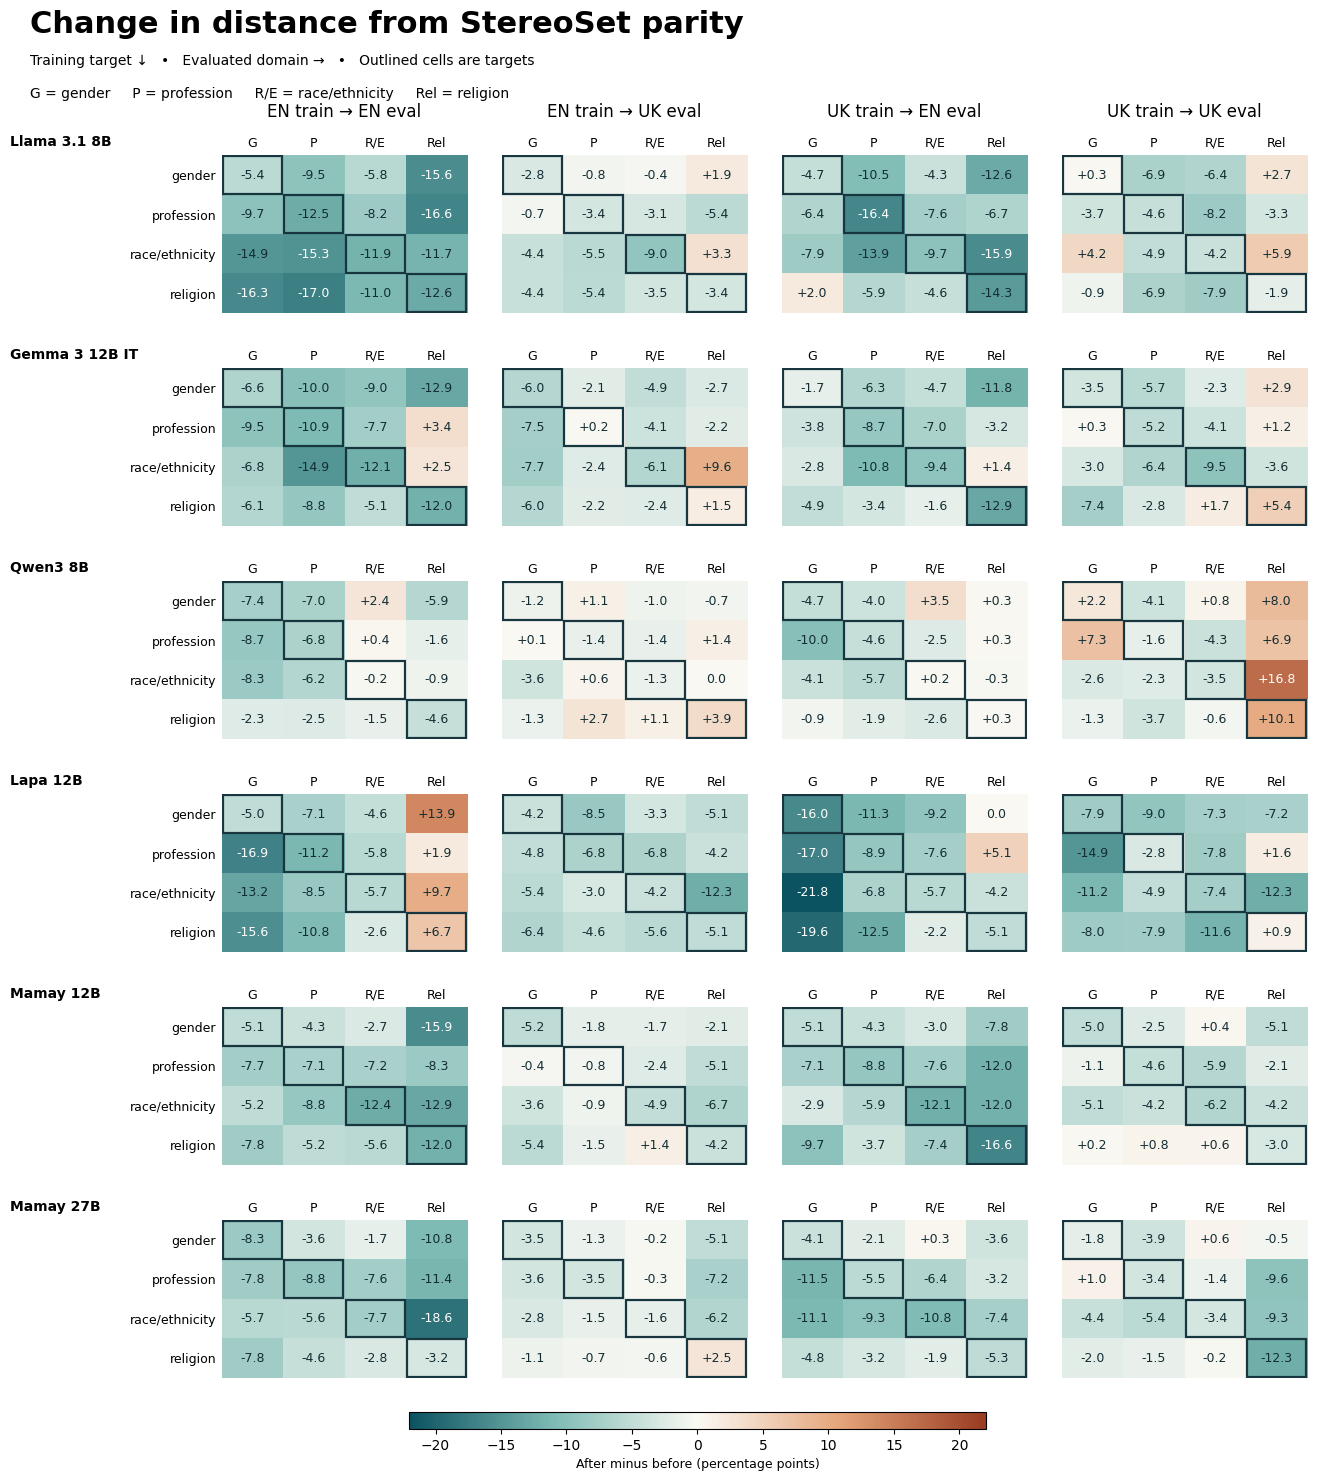

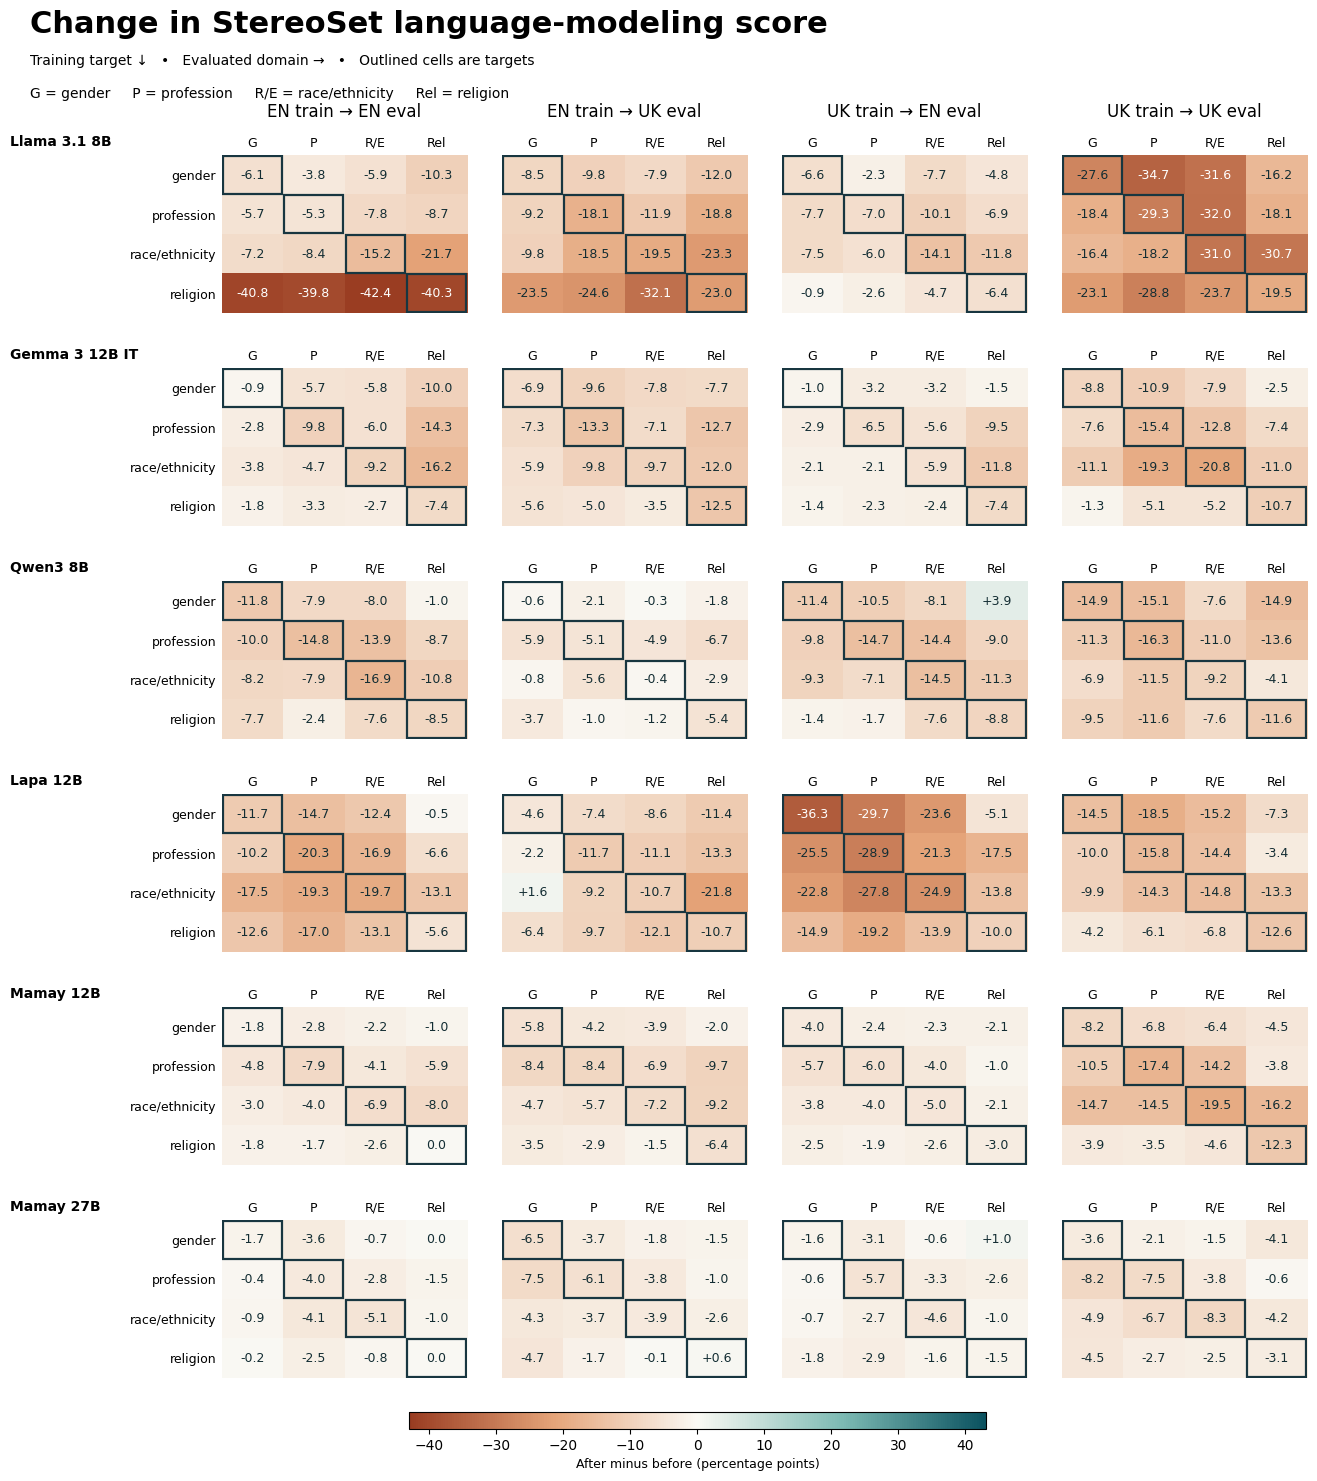

In [9]:
def heatmap(metric, title, good_sign, filename):
    limit = max(1, np.ceil(scores[metric].abs().max()))
    colors = ["#0b5260", "#7ebbb4", "#faf9f4", "#e5a479", "#993c21"]
    cmap = LinearSegmentedColormap.from_list(metric, colors if good_sign < 0 else colors[::-1])
    fig, axes = plt.subplots(len(models), len(routes), figsize=(13.4, 15.0))
    fig.subplots_adjust(left=0.17, right=0.98, top=0.89, bottom=0.075, wspace=0.14, hspace=0.35)
    fig.suptitle(title, x=0.027, y=0.987, ha="left", fontsize=22, weight="bold")
    fig.text(
        0.027, 0.950, "Training target ↓   •   Evaluated domain →   •   Outlined cells are targets"
    )
    fig.text(
        0.027, 0.928, "G = gender     P = profession     R/E = race/ethnicity     Rel = religion"
    )
    for i, model in enumerate(models):
        for j, (tr, ev) in enumerate(routes):
            ax = axes[i, j]
            panel = scores.loc[
                (scores.model == model) & (scores.train == tr) & (scores["eval"] == ev)
            ]
            values = panel.pivot(index="target", columns="evaluated", values=metric).loc[
                domains, domains
            ]
            mesh = ax.imshow(values, cmap=cmap, norm=Normalize(-limit, limit), aspect="auto")
            for (y, x), value in np.ndenumerate(values.to_numpy()):
                label = f"{value:+.1f}" if abs(value) >= 0.05 else "0.0"
                ax.text(
                    x,
                    y,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if abs(value) > 0.68 * limit else "#132D33",
                )
                if x == y:
                    ax.add_patch(
                        Rectangle(
                            (x - 0.48, y - 0.48), 0.96, 0.96, fill=False, color="#183640", lw=1.6
                        )
                    )
            ax.set_xticks(range(4), ["G", "P", "R/E", "Rel"], fontsize=9)
            ax.xaxis.tick_top()
            ax.set_yticks(
                range(4), [labels.get(d, d) for d in domains] if j == 0 else [""] * 4, fontsize=9
            )
            ax.tick_params(length=0, pad=4)
            ax.spines[:].set_visible(False)
            if i == 0:
                ax.set_title(f"{tr.upper()} train → {ev.upper()} eval", fontsize=12, pad=14)
        fig.text(
            0.012,
            axes[i, 0].get_position().y1 + 0.006,
            model.replace(" Instruct", ""),
            weight="bold",
        )
    bar = fig.colorbar(mesh, cax=fig.add_axes([0.31, 0.041, 0.43, 0.011]), orientation="horizontal")
    bar.set_label("After minus before (percentage points)", fontsize=9)
    fig.savefig(out / filename, dpi=160)
    plt.show()
    plt.close(fig)


heatmap("bias_change", "Change in distance from StereoSet parity", -1, "bias_heatmap.png")
heatmap("lms_change", "Change in StereoSet language-modeling score", 1, "lms_heatmap.png")

## WinoBias and BBQ
WinoBias reports the absolute pro–anti accuracy gap for occupational coreference. Controlled and natural are separate views. The natural views share 279 primary pairs. The Ukrainian panel also includes grammatical controls.

BBQ reports category-macro absolute bias separately by ambiguity condition. The category table preserves signed scores, eligible denominators and the non-unknown answer mass. A zero denominator can produce a convention-based endpoint with an unavailable paired change. Counts and means below use the native availability flag. The external CSV preserves pointwise paired intervals, valid bootstrap draws, accuracy and unknown-answer rates. Each external panel requested 1,000 draws.

In [10]:
external = external_rows(reports)
categories = bbq_categories(reports, external)
gaps = external.loc[
    ((external.scope == "overall_macro") & (external.metric == "absolute_bias_gap"))
    | (
        external.scope.str.startswith("category_macro / ")
        & (external.metric == "absolute_bias_macro")
    )
].copy()
gaps["panel"] = np.where(
    gaps.task.str.startswith("bbq"),
    "BBQ " + gaps.scope.str.split(" / ").str[-1],
    "WinoBias " + gaps.task.str.split("_").str[-1],
)
available = gaps.status.eq("available") & gaps.change.notna()
gaps["direction"] = np.select(
    [~available, gaps.change < -TOLERANCE, gaps.change > TOLERANCE],
    ["Unavailable", "Reduced", "Increased"],
    default="Unchanged",
)
display(
    pd.crosstab([gaps.panel, gaps["eval"]], gaps.direction).reindex(
        columns=["Reduced", "Increased", "Unchanged", "Unavailable"], fill_value=0
    )
)
external_means = (
    gaps.loc[available]
    .groupby(["model", "train", "eval", "panel"])
    .agg(before=("before", "mean"), after=("after", "mean"), available_targets=("change", "count"))
)
display(
    Markdown(
        "**Mean before → after across available training targets.** Counts in the exported summary identify missing BBQ comparisons."
    )
)
display(
    external_means.assign(score=before_after(external_means.before, external_means.after))
    .score.unstack("panel")
    .reindex(
        pd.MultiIndex.from_product([models, languages, languages], names=["model", "train", "eval"])
    )
)

direction                 Reduced  Increased  Unchanged  Unavailable
panel               eval                                            
BBQ ambiguous       en         38          7          0            3
                    uk         37          5          0            6
BBQ disambiguated   en         10         38          0            0
                    uk         14         34          0            0
WinoBias controlled en         28         20          0            0
                    uk         32         16          0            0
WinoBias natural    en         35         12          1            0
                    uk         43          5          0            0

**Mean before → after across available training targets.** Counts in the exported summary identify missing BBQ comparisons.

panel                            BBQ ambiguous BBQ disambiguated  \
model                 train eval                                   
Llama 3.1 8B Instruct en    en      15.6 → 2.4         3.2 → 4.3   
                            uk       9.5 → 1.8         3.5 → 3.4   
                      uk    en      15.6 → 4.1         3.2 → 3.6   
                            uk       9.5 → 1.3         3.5 → 2.7   
Gemma 3 12B IT        en    en      14.2 → 9.3         2.5 → 4.3   
                            uk       8.2 → 6.1         3.4 → 5.3   
                      uk    en     14.2 → 10.0         2.5 → 2.6   
                            uk       8.2 → 3.8         3.4 → 4.2   
Qwen3 8B              en    en       7.9 → 9.6         3.0 → 4.3   
                            uk       4.6 → 6.5         4.0 → 4.7   
                      uk    en       7.9 → 4.0         3.0 → 6.1   
                            uk       4.6 → 3.0         4.0 → 8.8   
Lapa 12B              en    en      22.6 → 6.7         2.6 → 4.7   
                            uk      10.7 → 3.6         3.3 → 5.1   
                      uk    en      22.6 → 9.8         2.6 → 4.5   
                            uk      10.7 → 6.6         3.3 → 6.0   
Mamay 12B             en    en      23.6 → 7.7         2.7 → 5.1   
                            uk       8.9 → 4.6         3.6 → 5.2   
                      uk    en     23.6 → 11.1         2.7 → 4.0   
                            uk       8.9 → 4.5         3.6 → 4.9   
Mamay 27B             en    en       9.1 → 4.3         3.0 → 5.4   
                            uk       9.0 → 4.2         2.8 → 5.9   
                      uk    en       9.1 → 6.2         3.0 → 5.0   
                            uk       9.0 → 5.4         2.8 → 4.4   

panel                            WinoBias controlled WinoBias natural  
model                 train eval                                       
Llama 3.1 8B Instruct en    en            41.5 → 2.9       63.3 → 5.2  
                            uk             6.0 → 2.3        2.2 → 0.5  
                      uk    en           41.5 → 13.6      63.3 → 15.7  
                            uk             6.0 → 0.0        2.2 → 2.1  
Gemma 3 12B IT        en    en           37.6 → 35.4      46.6 → 33.9  
                            uk           12.8 → 17.1       12.2 → 7.4  
                      uk    en           37.6 → 38.4      46.6 → 43.4  
                            uk           12.8 → 11.2       12.2 → 7.8  
Qwen3 8B              en    en           25.5 → 27.6      35.8 → 34.4  
                            uk             6.6 → 9.0       12.7 → 5.5  
                      uk    en           25.5 → 24.4      35.8 → 33.6  
                            uk             6.6 → 1.2       12.7 → 7.4  
Lapa 12B              en    en           41.8 → 12.3       47.0 → 8.9  
                            uk            12.7 → 3.9        9.7 → 1.5  
                      uk    en           41.8 → 36.3      47.0 → 33.3  
                            uk            12.7 → 8.8        9.7 → 6.5  
Mamay 12B             en    en           34.1 → 27.5      48.2 → 39.1  
                            uk           13.3 → 12.8       17.2 → 8.8  
                      uk    en           34.1 → 36.5      48.2 → 39.7  
                            uk           13.3 → 10.8       17.2 → 4.3  
Mamay 27B             en    en           21.5 → 22.7      33.2 → 30.6  
                            uk            8.5 → 10.2       12.5 → 8.6  
                      uk    en           21.5 → 24.7      33.2 → 32.6  
                            uk            8.5 → 11.1       12.5 → 8.0

### Row 17 · Signed BBQ bias by category

Ambiguous questions are the primary sheet result. Disambiguated questions provide a separate diagnostic. Each cell shows the native signed category score **before → after** in score points. Zero denotes balance. A positive score favors the stereotyped answer. Read a signed change together with distance from zero when a preference reverses.

Each displayed cell gives equal weight to the available paired scores among the four independently trained domain checkpoints for one model and language route. The fraction gives the number of available targets out of the four planned. Both means use the same available pairs. “Unavailable” means that no paired change was defined for that cell. Choose a model, training target, evaluation language, category and condition in `bbq_categories.csv` for the individual signed before/after values, paired change, eligible denominators, non-unknown mass, all-row accuracy, unknown-answer rates and native uncertainty. The category-macro absolute-bias table above answers a different question.

In [11]:
category_summary = summarize_bbq_categories(categories)
if not category_summary.total_targets.eq(len(domains)).all():
    raise ValueError("Each BBQ category must cover all four planned training targets")
denominators = (
    category_summary.available_targets.astype(str)
    + "/"
    + category_summary.total_targets.astype(str)
)
endpoints = before_after(category_summary.before, category_summary.after).where(
    category_summary.available_targets.gt(0), "Unavailable"
)
category_view = category_summary.assign(score=endpoints + " (" + denominators + ")")
for train, evaluation in routes:
    display(Markdown(f"#### {train.upper()} training → {evaluation.upper()} evaluation"))
    by_group = category_view.xs((train, evaluation), level=["train", "eval"]).score.unstack("model")
    display(by_group.reindex(columns=models))

#### EN training → EN evaluation

model                                 Llama 3.1 8B Instruct  \
condition     category                                        
ambiguous     Age                          39.4 → 3.2 (4/4)   
              Disability_status            19.0 → 4.3 (4/4)   
              Gender_identity              14.9 → 0.7 (4/4)   
              Gender_identity (names)      19.3 → 0.9 (4/4)   
              Nationality                  19.6 → 1.7 (4/4)   
              Physical_appearance          40.0 → 8.5 (4/4)   
              Race_ethnicity                5.3 → 0.7 (4/4)   
              Race_ethnicity (names)       6.9 → -0.2 (4/4)   
              Race_x_SES                   11.1 → 0.2 (4/4)   
              Race_x_SES (names)           7.1 → -0.4 (4/4)   
              Race_x_gender               -0.6 → -0.2 (4/4)   
              Race_x_gender (names)        6.1 → -0.6 (4/4)   
              Religion                     17.0 → 0.8 (4/4)   
              SES                          22.8 → 2.7 (4/4)   
              Sexual_orientation            4.4 → 0.7 (4/4)   
disambiguated Age                          1.3 → -0.6 (4/4)   
              Disability_status             2.6 → 7.9 (4/4)   
              Gender_identity               4.9 → 9.3 (4/4)   
              Gender_identity (names)       3.3 → 2.4 (4/4)   
              Nationality                   5.7 → 3.1 (4/4)   
              Physical_appearance          5.3 → 10.3 (4/4)   
              Race_ethnicity                0.7 → 2.7 (4/4)   
              Race_ethnicity (names)      -0.2 → -0.6 (4/4)   
              Race_x_SES                  -6.2 → -1.5 (4/4)   
              Race_x_SES (names)           2.7 → -0.2 (4/4)   
              Race_x_gender                 1.7 → 0.7 (4/4)   
              Race_x_gender (names)       -0.0 → -0.6 (4/4)   
              Religion                      9.7 → 1.2 (4/4)   
              SES                           2.5 → 4.1 (4/4)   
              Sexual_orientation            1.5 → 3.7 (4/4)   

model                                     Gemma 3 12B IT            Qwen3 8B  \
condition     category                                                         
ambiguous     Age                      36.2 → 23.8 (4/4)   30.5 → 29.7 (4/4)   
              Disability_status        27.6 → 12.6 (4/4)   19.9 → 16.3 (4/4)   
              Gender_identity           11.0 → 7.5 (4/4)     4.1 → 2.7 (4/4)   
              Gender_identity (names)   12.8 → 7.8 (4/4)     1.5 → 6.2 (4/4)   
              Nationality              19.4 → 11.5 (4/4)     4.3 → 7.8 (4/4)   
              Physical_appearance      19.3 → 17.4 (4/4)   16.2 → 29.9 (4/4)   
              Race_ethnicity             4.4 → 3.3 (4/4)     3.3 → 4.6 (4/4)   
              Race_ethnicity (names)     2.5 → 2.7 (4/4)     0.0 → 0.8 (4/4)   
              Race_x_SES                12.0 → 8.8 (4/4)     7.8 → 8.7 (4/4)   
              Race_x_SES (names)        11.1 → 8.4 (4/4)     6.8 → 3.4 (4/4)   
              Race_x_gender              0.3 → 0.1 (4/4)   -1.9 → -2.2 (4/4)   
              Race_x_gender (names)     -1.6 → 0.8 (4/4)   -0.9 → -1.9 (4/4)   
              Religion                 14.5 → 11.6 (4/4)    8.5 → 10.9 (4/4)   
              SES                      30.2 → 13.5 (4/4)   11.5 → 13.0 (4/4)   
              Sexual_orientation         9.5 → 5.7 (4/4)    -1.9 → 0.7 (4/4)   
disambiguated Age                        3.6 → 1.6 (4/4)     3.9 → 5.6 (4/4)   
              Disability_status          2.6 → 8.5 (4/4)     0.3 → 6.1 (4/4)   
              Gender_identity           3.9 → -4.6 (4/4)  -10.7 → -9.9 (4/4)   
              Gender_identity (names)    1.1 → 2.2 (4/4)     1.0 → 2.8 (4/4)   
              Nationality                3.6 → 3.7 (4/4)     1.0 → 2.9 (4/4)   
              Physical_appearance        1.9 → 1.1 (4/4)     6.4 → 7.6 (4/4)   
              Race_ethnicity            2.3 → -0.7 (4/4)   -0.6 → -0.6 (4/4)   
              Race_ethnicity (names)    0.4 → -0.2 (4/4)     0.

#### EN training → UK evaluation

model                                 Llama 3.1 8B Instruct  \
condition     category                                        
ambiguous     Age                         16.5 → -2.1 (4/4)   
              Disability_status            23.5 → 3.1 (4/4)   
              Gender_identity              9.3 → -0.5 (4/4)   
              Gender_identity (names)      8.0 → -0.8 (4/4)   
              Nationality                  5.2 → -0.0 (4/4)   
              Physical_appearance          39.3 → 3.1 (4/4)   
              Race_ethnicity               4.7 → -0.2 (4/4)   
              Race_ethnicity (names)       4.0 → -0.7 (4/4)   
              Race_x_SES                    5.0 → 2.4 (4/4)   
              Race_x_SES (names)            2.1 → 0.1 (4/4)   
              Race_x_gender                -1.4 → 0.3 (4/4)   
              Race_x_gender (names)        -0.8 → 0.4 (4/4)   
              Religion                     8.2 → -0.6 (4/4)   
              SES                          10.9 → 0.2 (4/4)   
              Sexual_orientation           3.5 → -2.5 (4/4)   
disambiguated Age                           3.0 → 0.2 (4/4)   
              Disability_status            15.1 → 5.7 (4/4)   
              Gender_identity             -0.5 → -3.5 (4/4)   
              Gender_identity (names)       3.5 → 0.7 (4/4)   
              Nationality                   4.5 → 1.2 (4/4)   
              Physical_appearance           2.3 → 8.4 (4/4)   
              Race_ethnicity               -0.1 → 4.1 (4/4)   
              Race_ethnicity (names)       -0.3 → 0.6 (4/4)   
              Race_x_SES                    1.8 → 1.4 (4/4)   
              Race_x_SES (names)            2.2 → 1.0 (4/4)   
              Race_x_gender               -0.4 → -0.6 (4/4)   
              Race_x_gender (names)       -1.6 → -1.7 (4/4)   
              Religion                      5.6 → 5.2 (4/4)   
              SES                          6.5 → -1.1 (4/4)   
              Sexual_orientation           5.0 → -3.9 (4/4)   

model                                     Gemma 3 12B IT           Qwen3 8B  \
condition     category                                                        
ambiguous     Age                      19.3 → 12.1 (4/4)  14.9 → 11.2 (4/4)   
              Disability_status         19.4 → 9.1 (4/4)  13.2 → 15.3 (4/4)   
              Gender_identity            3.4 → 3.6 (3/4)   7.6 → -1.7 (4/4)   
              Gender_identity (names)    6.2 → 2.3 (4/4)    0.8 → 0.6 (4/4)   
              Nationality               10.4 → 7.1 (4/4)    2.0 → 5.2 (4/4)   
              Physical_appearance      15.4 → 11.2 (4/4)  10.0 → 23.5 (4/4)   
              Race_ethnicity             2.6 → 3.2 (3/4)   -0.2 → 1.3 (4/4)   
              Race_ethnicity (names)     1.0 → 0.4 (4/4)   -0.2 → 0.6 (4/4)   
              Race_x_SES                 6.9 → 3.3 (4/4)    1.5 → 3.2 (4/4)   
              Race_x_SES (names)         4.8 → 3.1 (4/4)    3.1 → 1.7 (4/4)   
              Race_x_gender            -0.4 → -1.0 (3/4)  -2.4 → -1.2 (4/4)   
              Race_x_gender (names)    -4.7 → -1.0 (4/4)  -3.5 → -1.0 (4/4)   
              Religion                  10.8 → 8.3 (3/4)    3.3 → 7.1 (4/4)   
              SES                       12.0 → 4.4 (4/4)   6.5 → 11.4 (4/4)   
              Sexual_orientation         6.0 → 5.1 (3/4)   -0.2 → 2.5 (4/4)   
disambiguated Age                        7.9 → 6.8 (4/4)    4.7 → 2.5 (4/4)   
              Disability_status          8.0 → 3.6 (4/4)  10.5 → 11.5 (4/4)   
              Gender_identity          -9.8 → -2.6 (4/4)   -4.1 → 0.6 (4/4)   
              Gender_identity (names)    0.6 → 2.9 (4/4)    3.1 → 3.2 (4/4)   
              Nationality                4.7 → 4.2 (4/4)    2.2 → 2.9 (4/4)   
              Physical_appearance       0.7 → -2.5 (4/4)   6.6 → 11.3 (4/4)   
              Race_ethnicity             3.0 → 1.2 (4/4)   3.1 → -2.4 (4/4)   
              Race_ethnicity (names)    0.0 → -1.0 (4/4)    1.1 → 0.4 (4/4)   
        

#### UK training → EN evaluation

model                                 Llama 3.1 8B Instruct  \
condition     category                                        
ambiguous     Age                          39.4 → 5.2 (4/4)   
              Disability_status            19.0 → 4.5 (4/4)   
              Gender_identity              14.9 → 3.6 (4/4)   
              Gender_identity (names)      19.3 → 3.8 (4/4)   
              Nationality                  19.6 → 4.5 (4/4)   
              Physical_appearance         40.0 → 13.5 (4/4)   
              Race_ethnicity                5.3 → 1.2 (4/4)   
              Race_ethnicity (names)        6.9 → 1.7 (4/4)   
              Race_x_SES                   11.1 → 3.5 (4/4)   
              Race_x_SES (names)            7.1 → 1.7 (4/4)   
              Race_x_gender               -0.6 → -0.1 (4/4)   
              Race_x_gender (names)         6.1 → 0.7 (4/4)   
              Religion                     17.0 → 5.5 (4/4)   
              SES                          22.8 → 3.9 (4/4)   
              Sexual_orientation            4.4 → 3.6 (4/4)   
disambiguated Age                           1.3 → 1.2 (4/4)   
              Disability_status             2.6 → 7.0 (4/4)   
              Gender_identity               4.9 → 3.3 (4/4)   
              Gender_identity (names)       3.3 → 1.9 (4/4)   
              Nationality                   5.7 → 2.3 (4/4)   
              Physical_appearance           5.3 → 7.3 (4/4)   
              Race_ethnicity               0.7 → -2.3 (4/4)   
              Race_ethnicity (names)      -0.2 → -0.2 (4/4)   
              Race_x_SES                  -6.2 → -0.6 (4/4)   
              Race_x_SES (names)           2.7 → -0.1 (4/4)   
              Race_x_gender                 1.7 → 0.2 (4/4)   
              Race_x_gender (names)        -0.0 → 0.5 (4/4)   
              Religion                      9.7 → 3.2 (4/4)   
              SES                           2.5 → 0.7 (4/4)   
              Sexual_orientation           1.5 → -2.1 (4/4)   

model                                     Gemma 3 12B IT             Qwen3 8B  \
condition     category                                                          
ambiguous     Age                      36.2 → 20.9 (4/4)    30.5 → 10.8 (4/4)   
              Disability_status        27.6 → 18.5 (4/4)     19.9 → 9.7 (3/4)   
              Gender_identity           11.0 → 4.4 (4/4)     4.1 → -1.8 (3/4)   
              Gender_identity (names)   12.8 → 9.0 (4/4)      1.5 → 1.5 (3/4)   
              Nationality              19.4 → 12.7 (4/4)      4.3 → 1.1 (3/4)   
              Physical_appearance      19.3 → 17.9 (4/4)     16.2 → 7.6 (4/4)   
              Race_ethnicity             4.4 → 4.5 (4/4)      3.3 → 1.8 (3/4)   
              Race_ethnicity (names)     2.5 → 1.5 (4/4)     0.0 → -0.4 (3/4)   
              Race_x_SES               12.0 → 11.0 (4/4)      7.8 → 2.5 (3/4)   
              Race_x_SES (names)        11.1 → 9.2 (4/4)      6.8 → 2.1 (4/4)   
              Race_x_gender              0.3 → 0.4 (4/4)    -1.9 → -0.5 (4/4)   
              Race_x_gender (names)     -1.6 → 0.1 (4/4)    -0.9 → -1.1 (3/4)   
              Religion                 14.5 → 14.3 (4/4)      8.5 → 4.9 (3/4)   
              SES                      30.2 → 16.9 (4/4)     11.5 → 2.7 (4/4)   
              Sexual_orientation         9.5 → 6.9 (4/4)    -1.9 → -0.3 (3/4)   
disambiguated Age                        3.6 → 0.6 (4/4)      3.9 → 8.9 (4/4)   
              Disability_status          2.6 → 0.9 (4/4)      0.3 → 4.7 (4/4)   
              Gender_identity           3.9 → -3.7 (4/4)  -10.7 → -15.0 (4/4)   
              Gender_identity (names)    1.1 → 1.7 (4/4)     1.0 → -1.6 (4/4)   
              Nationality                3.6 → 2.3 (4/4)      1.0 → 0.9 (4/4)   
              Physical_appearance        1.9 → 2.0 (4/4)     6.4 → 13.9 (4/4)   
              Race_ethnicity             2.3 → 0.8 (4/4)     -0.6 → 7.6 (4/4)   
              Race_ethnicity (names)   

#### UK training → UK evaluation

model                                 Llama 3.1 8B Instruct  \
condition     category                                        
ambiguous     Age                          16.5 → 0.2 (4/4)   
              Disability_status           23.5 → -0.2 (4/4)   
              Gender_identity              9.3 → -0.6 (4/4)   
              Gender_identity (names)       8.0 → 0.1 (4/4)   
              Nationality                   5.2 → 0.6 (4/4)   
              Physical_appearance          39.3 → 1.4 (4/4)   
              Race_ethnicity                4.7 → 1.4 (4/4)   
              Race_ethnicity (names)        4.0 → 0.8 (4/4)   
              Race_x_SES                    5.0 → 0.0 (4/4)   
              Race_x_SES (names)           2.1 → -0.3 (4/4)   
              Race_x_gender               -1.4 → -0.0 (4/4)   
              Race_x_gender (names)        -0.8 → 0.3 (4/4)   
              Religion                      8.2 → 0.5 (4/4)   
              SES                          10.9 → 1.0 (4/4)   
              Sexual_orientation            3.5 → 0.0 (4/4)   
disambiguated Age                          3.0 → -1.7 (4/4)   
              Disability_status            15.1 → 3.1 (4/4)   
              Gender_identity              -0.5 → 1.3 (4/4)   
              Gender_identity (names)       3.5 → 0.7 (4/4)   
              Nationality                   4.5 → 3.9 (4/4)   
              Physical_appearance           2.3 → 3.7 (4/4)   
              Race_ethnicity               -0.1 → 0.9 (4/4)   
              Race_ethnicity (names)       -0.3 → 1.3 (4/4)   
              Race_x_SES                    1.8 → 2.3 (4/4)   
              Race_x_SES (names)            2.2 → 1.1 (4/4)   
              Race_x_gender               -0.4 → -1.7 (4/4)   
              Race_x_gender (names)       -1.6 → -0.4 (4/4)   
              Religion                      5.6 → 3.1 (4/4)   
              SES                           6.5 → 3.4 (4/4)   
              Sexual_orientation           5.0 → -0.2 (4/4)   

model                                      Gemma 3 12B IT            Qwen3 8B  \
condition     category                                                          
ambiguous     Age                        19.3 → 6.9 (4/4)    14.9 → 1.8 (4/4)   
              Disability_status          19.4 → 9.3 (4/4)    13.2 → 9.0 (4/4)   
              Gender_identity             3.4 → 1.0 (4/4)    7.6 → -1.7 (3/4)   
              Gender_identity (names)     6.2 → 2.2 (4/4)     0.8 → 0.7 (3/4)   
              Nationality                10.4 → 4.5 (4/4)     2.0 → 1.2 (4/4)   
              Physical_appearance        15.4 → 9.8 (4/4)    10.0 → 8.0 (4/4)   
              Race_ethnicity              2.6 → 2.2 (4/4)    -0.2 → 0.0 (4/4)   
              Race_ethnicity (names)      1.0 → 0.6 (4/4)   -0.2 → -0.0 (4/4)   
              Race_x_SES                  6.9 → 3.1 (4/4)    1.5 → -0.5 (3/4)   
              Race_x_SES (names)          4.8 → 2.8 (4/4)     3.1 → 0.5 (4/4)   
              Race_x_gender             -0.4 → -0.0 (4/4)    -2.4 → 0.1 (3/4)   
              Race_x_gender (names)     -4.7 → -1.5 (4/4)   -3.5 → -0.3 (3/4)   
              Religion                   10.8 → 6.4 (4/4)     3.3 → 1.9 (4/4)   
              SES                        12.0 → 2.6 (4/4)    6.5 → -1.1 (4/4)   
              Sexual_orientation          6.0 → 2.9 (4/4)    -0.2 → 0.7 (3/4)   
disambiguated Age                         7.9 → 7.0 (4/4)     4.7 → 4.3 (4/4)   
              Disability_status           8.0 → 6.1 (4/4)   10.5 → 10.8 (4/4)   
              Gender_identity          -9.8 → -10.7 (4/4)    -4.1 → 6.4 (4/4)   
              Gender_identity (names)     0.6 → 1.6 (4/4)     3.1 → 0.6 (4/4)   
              Nationality                 4.7 → 3.1 (4/4)     2.2 → 1.1 (4/4)   
              Physical_appearance         0.7 → 2.8 (4/4)     6.6 → 6.4 (4/4)   
              Race_ethnicity              3.0 → 1.8 (4/4)     3.1 → 7.7 (4/4)   
              Race_ethnicity (names)   

#### Inspect one checkpoint

The example below opens one English-trained Gemma race/ethnicity checkpoint on Ukrainian ambiguous questions. Change the selectors to inspect any checkpoint or condition. The endpoint and accuracy columns show **before → after**. Accuracy uses all source rows. Bias uses eligible rows and needs non-unknown answer mass. A missing paired change is explicitly marked unavailable, even if the scorer recorded a convention-based numeric endpoint.

In [12]:
example_model = "Gemma 3 12B IT"
example_train, example_eval, example_target = "en", "uk", "race"
example_condition = "ambiguous"
example = (
    categories.set_index(KEY + ["condition"])
    .sort_index()
    .loc[(example_model, example_train, example_eval, example_target, example_condition)]
    .set_index("category")
    .sort_index()
)
display(
    pd.DataFrame(
        {
            "Signed bias": before_after(example.before, example.after),
            "Paired Δ": example.change,
            "All rows": example.all_rows_before,
            "Eligible rows": example.eligible_before,
            "Non-unknown mass": before_after(
                example.non_unknown_mass_before, example.non_unknown_mass_after
            ),
            "Accuracy %": before_after(example.accuracy_before, example.accuracy_after),
            "Status": example.status,
        }
    ).round(2)
)

,Signed bias,Paired Δ,All rows,Eligible rows,Non-unknown mass,Accuracy %,Status
category,,,,,,,
Age,19.3 → 1.0,-18.32,1840,1840,871.0 → 78.0,52.7 → 95.8,available
Disability_status,19.4 → 2.9,-16.52,778,778,237.0 → 61.5,69.5 → 92.1,available
Gender_identity,3.4 → 0.0,NaN,336,328,13.0 → 0.0,95.8 → 100.0,unavailable
Gender_identity (names),6.2 → 0.5,-5.66,2500,2500,298.5 → 47.0,88.1 → 98.1,available
Nationality,10.4 → 0.0,-10.39,1540,1540,346.0 → 10.0,77.5 → 99.4,available
Physical_appearance,15.4 → 1.8,-13.58,788,788,139.0 → 18.0,82.4 → 97.7,available
Race_ethnicity,2.6 → 0.0,NaN,940,940,78.0 → 0.0,91.7 → 100.0,unavailable
Race_ethnicity (names),1.0 → 0.3,-0.72,2500,2500,464.0 → 44.0,81.4 → 98.2,available
Race_x_SES,6.9 → 0.6,-6.31,1680,1680,150.0 → 16.0,91.1 → 99.0,available


### Does the model select “unknown” when BBQ gives the answer?

Fair-UK scored the three options in three cyclic orders and split credit for tied winners. On ambiguous questions, “unknown” is correct. On disambiguated questions, the context identifies the answer, so an increase in the unknown-option rate means more forced-choice abstention. The comparison below pools all items in each condition. The CSV contains all checkpoints in both evaluation languages, including native paired intervals where available. Category-specific rates are in `bbq_categories.csv`.

A refusal such as “I can’t answer that question” would require the model to generate a response. The original BBQ evaluation recorded only option scores. The same released questions could be used for a separate free-response evaluation.

In [13]:
unknown_rates = external.loc[
    external.task.isin(["bbq_en", "bbq_uk"])
    & external.metric.eq("unknown_rate")
    & external.scope.isin(["pooled_all / ambiguous", "pooled_all / disambiguated"])
].copy()
unknown_rates["condition"] = unknown_rates.scope.str.split(" / ").str[-1]
unknown_rates = unknown_rates[
    KEY + ["condition", "before", "after", "change", "ci_low", "ci_high", "status", "uncertainty"]
].sort_values(KEY + ["condition"])
expected = set(product(models, ("en", "uk"), ("en", "uk"), domains, ("ambiguous", "disambiguated")))
keys = unknown_rates[KEY + ["condition"]]
if keys.duplicated().any() or set(keys.itertuples(index=False, name=None)) != expected:
    raise ValueError("Incomplete BBQ unknown-option comparisons")
display(
    unknown_rates.loc[
        unknown_rates.model.eq("Gemma 3 12B IT")
        & unknown_rates.train.eq("en")
        & unknown_rates.target.eq("gender"),
        ["eval", "condition", "before", "after", "change", "ci_low", "ci_high"],
    ]
    .set_index(["eval", "condition"])
    .round(2)
)

before  after  change  ci_low  ci_high
eval condition                                            
en   ambiguous       68.97  53.63  -15.34  -18.54   -12.18
     disambiguated    3.82   6.12    2.30    1.07     3.62
uk   ambiguous       80.98  78.61   -2.37   -4.53     0.09
     disambiguated    6.84  13.81    6.97    5.01     8.83

### Accuracy alongside the external bias measures
Each row counts checkpoint comparisons in one evaluation language. A smaller WinoBias gap can accompany lower primary coreference accuracy. For BBQ, accuracy covers all rows in each condition. The last column counts comparisons with both an available bias reduction and an accuracy loss.

In [14]:
accuracy = external.loc[
    ((external.scope == "overall_macro") & (external.metric == "primary_accuracy"))
    | (external.scope.str.startswith("pooled_all / ") & (external.metric == "accuracy_all_rows"))
].copy()
accuracy["panel"] = np.where(
    accuracy.task.str.startswith("bbq"),
    "BBQ " + accuracy.scope.str.split(" / ").str[-1],
    "WinoBias " + accuracy.task.str.split("_").str[-1],
)
accuracy = accuracy.rename(
    columns={c: "accuracy_" + c for c in ["before", "after", "change", "status"]}
)
paired_external = gaps.merge(
    accuracy[
        KEY + ["panel", "accuracy_before", "accuracy_after", "accuracy_change", "accuracy_status"]
    ],
    on=KEY + ["panel"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)
if not paired_external["_merge"].eq("both").all():
    raise ValueError("External bias and accuracy cover different checkpoints or panels")
paired_external = paired_external.drop(columns="_merge")
paired_external["accuracy_fell"] = paired_external.accuracy_change.lt(-TOLERANCE)
paired_external["bias_and_accuracy_fell"] = (
    paired_external.direction.eq("Reduced") & paired_external.accuracy_fell
)
display(
    paired_external.groupby(["panel", "eval"]).agg(
        comparisons=("direction", "size"),
        lower_accuracy=("accuracy_fell", "sum"),
        lower_bias_and_accuracy=("bias_and_accuracy_fell", "sum"),
    )
)

comparisons  lower_accuracy  lower_bias_and_accuracy
panel               eval                                                      
BBQ ambiguous       en             48              21                       14
                    uk             48              21                       16
BBQ disambiguated   en             48              48                       10
                    uk             48              47                       13
WinoBias controlled en             48              39                       22
                    uk             48              42                       26
WinoBias natural    en             48              46                       33
                    uk             48              40                       36

## Row 18 · Training imbalance by named StereoSet target

Each calculation uses one checkpoint, one evaluation language and the named targets in its trained domain. Exposure counts come from the two original Ethos streams and stay separate. Each full epoch traversed the packed blocks on one process. We reconstructed each item’s retained tokens with the training tokenizer, removed the first causal label of each block, and checked totals against the archived budgets and completed steps. A source item counts once per stream if it contributed at least one predicted label. Valid-label exposure also counts repetitions across epochs.

The outcome is change in each named target’s absolute distance from SS = 50, in percentage points. Spearman’s ρ uses the groups’ exposure and paired outcomes, including evaluated groups with zero exposure. The two covariates are distinct item count and valid-label count. The table shows point estimates and support. A constant input or outcome has no defined correlation. These are single-seed StereoSet estimates within a domain.

In [15]:
from study_metrics import domain_ri_inputs, exposure_tables, metric_values

streams, named_groups, margins, imbalance = exposure_tables(study, reports)
ri_components = domain_ri_inputs(scores, target)
values = metric_values(target, scores, transfer, categories, imbalance)
display(
    imbalance.loc[imbalance.exposure.eq("distinct_items")]
    .pivot(index=KEY + ["groups"], columns="stream", values="rho")
    .round(3)
)

stream                                       antistereo  stereo
model          train eval target     groups                    
Gemma 3 12B IT en    en   gender     10           0.755   0.755
                          profession 30          -0.024  -0.024
                          race       36          -0.296  -0.292
                          religion   3            0.500   0.500
                     uk   gender     10           0.593   0.606
...                                                 ...     ...
Qwen3 8B       uk    en   religion   3           -1.000  -1.000
                     uk   gender     10           0.034  -0.012
                          profession 30          -0.158  -0.158
                          race       36           0.005   0.002
                          religion   3            1.000   1.000

[96 rows x 2 columns]

## Calibrated NNR and RI for each checkpoint

NNR uses held-out items whose baseline margin exceeds the language-specific threshold. Neutralized items end within the inclusive band. Reversed items end below the negative threshold. We subtract the reversed fraction from the neutralized fraction, first within semantic family and then with equal weight across eligible families.

The intervals use 2,000 shared Bayesian bootstrap draws over the held-out semantic families. Each draw gives a family the same weight across its items, languages and phases. Native SS retains equal weighting across named targets. RI intervals condition on draws with a positive denominator. The table records the number of these draws and the reason for each undefined RI. Intervals are pointwise, conditional on calibration and on the single training seed.

In [16]:
from calibrated_metrics import append_calibrated_values, calculated_metrics, checkpoint_results

thresholds, nnr, sensitivity, domain_ri, language_ri, ri_contributions = calculated_metrics(
    study, reports, scores, margins
)
paired_metrics = checkpoint_results(nnr, domain_ri)
values = append_calibrated_values(values, nnr, domain_ri, language_ri)
display(thresholds.pivot(index=["model", "eval"], columns="quantile", values="tau").round(5))
for route in routes:
    rows = paired_metrics.loc[
        paired_metrics.train.eq(route[0]) & paired_metrics["eval"].eq(route[1])
    ]
    display(Markdown(f"### {route[0].upper()} training · {route[1].upper()} evaluation"))
    display(
        rows.set_index(["model", "target"])[
            [
                "tau",
                "eligible",
                "nnr",
                "nnr_low",
                "nnr_high",
                "numerator",
                "target_reduction",
                "domain_ri",
                "ri_status",
            ]
        ].round(4)
    )
display(language_ri.groupby(["train", "status"]).size().rename("checkpoints").to_frame())

quantile                        0.1      0.2      0.3
model                 eval                           
Gemma 3 12B IT        en    0.06250  0.07895  0.15000
                      uk    0.10714  0.14545  0.22262
Lapa 12B              en    0.06250  0.11765  0.22727
                      uk    0.24375  0.39667  0.52525
Llama 3.1 8B Instruct en    0.08333  0.10714  0.16667
                      uk    0.10417  0.15517  0.24603
Mamay 12B             en    0.03571  0.07143  0.15909
                      uk    0.05000  0.11111  0.17510
Mamay 27B             en    0.07692  0.12500  0.18182
                      uk    0.06250  0.08333  0.16883
Qwen3 8B              en    0.04091  0.16667  0.25000
                      uk    0.12011  0.17565  0.21344

### EN training · EN evaluation

tau  eligible     nnr  nnr_low  nnr_high  \
model                 target                                                    
Gemma 3 12B IT        gender      0.0789        75 -0.0944  -0.2475   -0.0157   
                      profession  0.0789       239 -0.1616  -0.2608   -0.0783   
                      race        0.0789       270 -0.0810  -0.1728    0.0108   
                      religion    0.0789        18 -0.0595  -0.1564   -0.0079   
Lapa 12B              gender      0.1176        67 -0.0559  -0.2503    0.1179   
                      profession  0.1176       211 -0.2498  -0.3614   -0.1412   
                      race        0.1176       256 -0.0754  -0.1679    0.0129   
                      religion    0.1176        19  0.0417  -0.1581    0.3521   
Llama 3.1 8B Instruct gender      0.1071        62  0.0125  -0.1363    0.1676   
                      profession  0.1071       210  0.0496  -0.0565    0.1523   
                      race        0.1071       238  0.0764  -0.0246    0.1806   
                      religion    0.1071        16 -0.2000  -0.6172    0.2643   
Mamay 12B             gender      0.0714        74  0.0245   0.0017    0.0866   
                      profession  0.0714       232  0.0014  -0.0840    0.0868   
                      race        0.0714       273  0.0786  -0.0027    0.1653   
                      religion    0.0714        19  0.0260  -0.0351    0.1380   
Mamay 27B             gender      0.1250        69  0.0782   0.0124    0.2073   
                      profession  0.1250       207  0.1295   0.0357    0.2293   
                      race        0.1250       250  0.0929   0.0245    0.1732   
                      religion    0.1250        20  0.1481   0.0171    0.3825   
Qwen3 8B              gender      0.1667        59  0.0763  -0.0900    0.2665   
                      profession  0.1667       185  0.0790  -0.0438    0.1948   
                      race        0.1667       169  0.2071   0.0968    0.3280   
                      religion    0.1667        11  0.2500   0.0348    0.5981   

                                  numerator  target_reduction  domain_ri  \
model                 target                                               
Gemma 3 12B IT        gender         0.0000            6.6364     0.0000   
                      profession     1.1490           10.9292     0.1051   
                      race           0.8333           12.1373     0.0687   
                      religion       0.0000           11.9697        NaN   
Lapa 12B              gender         4.6212            5.0328        NaN   
                      profession     0.6313           11.2427     0.0562   
                      race           3.2323            5.7247     0.5646   
                      religion       0.0000           -6.6667        NaN   
Llama 3.1 8B Instruct gender         0.0000            5.4293     0.0000   
                      profession     0.0000           12.4781     0.0000   
                      race           0.0000           11.8587     0.0000   
                      religion       0.0000           12.6136     0.0000   
Mamay 12B             gender         0.0000            5.0619     0.0000   
                      profession     0.0000            7.0637     0.0000   
                      race           0.0000           12.4341     0.0000   
                      religion       0.0000           11.9697        NaN   
Mamay 27B             gender         0.0000            8.3497     0.0000   
                      profession     0.0000            8.8026     0.0000   
                      race           0.0000            7.7250     0.0000   
                      religion       0.0000            3.2197        NaN   
Qwen3 8B              gender         0.8099            7.3813     0.1097   
                      profession     0.1302            6.7898     0.0192   
                      race           0.0000            0.1862        NaN   
                      religion

### EN training · UK evaluation

tau  eligible     nnr  nnr_low  nnr_high  \
model                 target                                                    
Gemma 3 12B IT        gender      0.1455        53  0.2500  -0.0283    0.5179   
                      profession  0.1455       167  0.1045   0.0186    0.2020   
                      race        0.1455       231  0.0473  -0.0293    0.1219   
                      religion    0.1455        14 -0.0222  -0.0659   -0.0006   
Lapa 12B              gender      0.3967        49  0.1719  -0.0448    0.4085   
                      profession  0.3967       126  0.1536   0.0373    0.2859   
                      race        0.3967       185  0.1279   0.0381    0.2248   
                      religion    0.3967        13  0.3061   0.0686    0.6507   
Llama 3.1 8B Instruct gender      0.1552        47  0.2146  -0.1329    0.5397   
                      profession  0.1552       153  0.1667   0.0510    0.2861   
                      race        0.1552       203  0.1180   0.0020    0.2290   
                      religion    0.1552        14 -0.5370  -0.9398    0.1538   
Mamay 12B             gender      0.1111        46  0.1935   0.0526    0.4044   
                      profession  0.1111       171  0.0897   0.0083    0.1832   
                      race        0.1111       236  0.0591  -0.0059    0.1278   
                      religion    0.1111        18  0.4444   0.1653    0.7564   
Mamay 27B             gender      0.0833        51  0.1300   0.0339    0.2895   
                      profession  0.0833       189  0.1105   0.0082    0.2225   
                      race        0.0833       258  0.0664   0.0298    0.1208   
                      religion    0.0833        19  0.1313   0.0145    0.3893   
Qwen3 8B              gender      0.1757        26  0.2471   0.0550    0.5127   
                      profession  0.1757       134  0.1049   0.0057    0.2131   
                      race        0.1757       182  0.1813   0.1013    0.2712   
                      religion    0.1757        11  0.0286   0.0008    0.0832   

                                  numerator  target_reduction  domain_ri  \
model                 target                                               
Gemma 3 12B IT        gender         0.0000            5.9861        NaN   
                      profession     0.0000           -0.2215        NaN   
                      race           3.2071            6.1250     0.5236   
                      religion       0.0000           -1.4773        NaN   
Lapa 12B              gender         0.0000            4.2071        NaN   
                      profession     0.0000            6.8487     0.0000   
                      race           0.0000            4.1989        NaN   
                      religion       0.0000            5.1136     0.0000   
Llama 3.1 8B Instruct gender         0.6313            2.8157        NaN   
                      profession     0.0000            3.3847        NaN   
                      race           1.0859            9.0468     0.1200   
                      religion       0.0000            3.4091        NaN   
Mamay 12B             gender         0.0000            5.1578        NaN   
                      profession     0.0000            0.7881        NaN   
                      race           0.0000            4.9338     0.0000   
                      religion       0.4576            4.1667        NaN   
Mamay 27B             gender         0.0000            3.5480        NaN   
                      profession     0.0000            3.5356     0.0000   
                      race           0.0000            1.5890        NaN   
                      religion       0.0000           -2.5000        NaN   
Qwen3 8B              gender         0.3783            1.1515        NaN   
                      profession     0.4823            1.4337        NaN   
                      race           0.2155            1.3168        NaN   
                      religion

### UK training · EN evaluation

tau  eligible     nnr  nnr_low  nnr_high  \
model                 target                                                    
Gemma 3 12B IT        gender      0.0789        75  0.0035  -0.1319    0.1325   
                      profession  0.0789       239  0.0375  -0.0660    0.1356   
                      race        0.0789       270  0.0006  -0.0730    0.0745   
                      religion    0.0789        18 -0.0238  -0.1368    0.0413   
Lapa 12B              gender      0.1176        67 -0.5099  -0.7233   -0.3080   
                      profession  0.1176       211 -0.1706  -0.2742   -0.0716   
                      race        0.1176       256 -0.1588  -0.2507   -0.0707   
                      religion    0.1176        19 -0.1354  -0.4125    0.0340   
Llama 3.1 8B Instruct gender      0.1071        62  0.1441  -0.0504    0.3594   
                      profession  0.1071       210  0.0945  -0.0166    0.2062   
                      race        0.1071       238  0.1485   0.0439    0.2563   
                      religion    0.1071        16  0.1000  -0.2268    0.4271   
Mamay 12B             gender      0.0714        74  0.0455  -0.0495    0.1735   
                      profession  0.0714       232  0.0057  -0.0859    0.1020   
                      race        0.0714       273  0.0508  -0.0189    0.1227   
                      religion    0.0714        19 -0.0417  -0.1448   -0.0012   
Mamay 27B             gender      0.1250        69  0.0803   0.0135    0.2200   
                      profession  0.1250       207  0.1714   0.0705    0.2781   
                      race        0.1250       250  0.0793   0.0154    0.1457   
                      religion    0.1250        20  0.0370   0.0009    0.1198   
Qwen3 8B              gender      0.1667        59  0.2103   0.0704    0.4057   
                      profession  0.1667       185  0.2015   0.0937    0.3112   
                      race        0.1667       169  0.2764   0.1754    0.3785   
                      religion    0.1667        11  0.1111  -0.1354    0.4728   

                                  numerator  target_reduction  domain_ri  \
model                 target                                               
Gemma 3 12B IT        gender         0.0000            1.7008        NaN   
                      profession     0.0000            8.7446     0.0000   
                      race           0.4545            9.4225     0.0482   
                      religion       0.0000           12.9167        NaN   
Lapa 12B              gender         0.0000           16.0391     0.0000   
                      profession     1.7045            8.8835     0.1919   
                      race           0.0000            5.7074     0.0000   
                      religion       0.0000            5.1136        NaN   
Llama 3.1 8B Instruct gender         0.0000            4.7121        NaN   
                      profession     0.0000           16.4464     0.0000   
                      race           0.0000            9.6682     0.0000   
                      religion       0.6536           14.2803        NaN   
Mamay 12B             gender         0.0000            5.0960        NaN   
                      profession     0.0000            8.7950     0.0000   
                      race           0.0000           12.1099     0.0000   
                      religion       0.0000           16.5530        NaN   
Mamay 27B             gender         0.1156            4.1301        NaN   
                      profession     0.0000            5.4681     0.0000   
                      race           0.0000           10.7738     0.0000   
                      religion       0.0000            5.3030        NaN   
Qwen3 8B              gender         1.2627            4.7083        NaN   
                      profession     0.1010            4.5565        NaN   
                      race           0.0000           -0.1834        NaN   
                      religion

### UK training · UK evaluation

tau  eligible     nnr  nnr_low  nnr_high  \
model                 target                                                    
Gemma 3 12B IT        gender      0.1455        53  0.1184  -0.1753    0.3874   
                      profession  0.1455       167  0.0611  -0.0513    0.1755   
                      race        0.1455       231  0.0513  -0.0543    0.1590   
                      religion    0.1455        14  0.0222   0.0006    0.0659   
Lapa 12B              gender      0.3967        49  0.0556  -0.2702    0.3688   
                      profession  0.3967       126  0.0812  -0.0236    0.1936   
                      race        0.3967       185  0.0180  -0.0863    0.1252   
                      religion    0.3967        13  0.0612   0.0017    0.1916   
Llama 3.1 8B Instruct gender      0.1552        47  0.0833  -0.2682    0.4094   
                      profession  0.1552       153 -0.0308  -0.2095    0.1463   
                      race        0.1552       203 -0.1257  -0.2867    0.0360   
                      religion    0.1552        14  0.2037  -0.3299    0.6763   
Mamay 12B             gender      0.1111        46  0.1331  -0.1040    0.3774   
                      profession  0.1111       171  0.0240  -0.0770    0.1298   
                      race        0.1111       236  0.0082  -0.0582    0.0766   
                      religion    0.1111        18  0.3444   0.1036    0.6492   
Mamay 27B             gender      0.0833        51  0.0783   0.0125    0.2047   
                      profession  0.0833       189  0.1771   0.0692    0.2899   
                      race        0.0833       258  0.0379  -0.0251    0.1040   
                      religion    0.0833        19  0.0000  -0.2949    0.3079   
Qwen3 8B              gender      0.1757        26 -0.1059  -0.4391    0.2285   
                      profession  0.1757       134  0.2184   0.0662    0.3754   
                      race        0.1757       182  0.2801   0.1749    0.3939   
                      religion    0.1757        11  0.2857   0.0411    0.6577   

                                  numerator  target_reduction  domain_ri  \
model                 target                                               
Gemma 3 12B IT        gender         0.9722            3.5366        NaN   
                      profession     0.5088            5.2434     0.0970   
                      race           0.0000            9.5020     0.0000   
                      religion       0.5631           -5.4167        NaN   
Lapa 12B              gender         0.0000            7.8939     0.0000   
                      profession     0.5177            2.8190        NaN   
                      race           0.0000            7.4435     0.0000   
                      religion       0.0000           -0.9470        NaN   
Llama 3.1 8B Instruct gender         0.9091           -0.2866        NaN   
                      profession     0.0000            4.6361        NaN   
                      race           3.3868            4.1558        NaN   
                      religion       0.0000            1.8561        NaN   
Mamay 12B             gender         0.1223            5.0088        NaN   
                      profession     0.0000            4.6419     0.0000   
                      race           0.0000            6.2104     0.0000   
                      religion       0.5287            3.0303        NaN   
Mamay 27B             gender         0.2095            1.8472        NaN   
                      profession     0.3199            3.4398     0.0930   
                      race           0.0000            3.4363        NaN   
                      religion       0.0000           12.3106        NaN   
Qwen3 8B              gender         2.9459           -2.1881        NaN   
                      profession     4.7403            1.5568        NaN   
                      race           5.5934            3.4507     1.6209   
                      religion

checkpoints
train status                                        
en    available                                   17
      below_or_equal_practical_minimum             2
      denominator_interval_reaches_zero            5
uk    available                                    8
      below_or_equal_practical_minimum             5
      denominator_interval_reaches_zero           11

## Numerical results

The full-precision table contains each calculated study metric at its reported level. For forget efficacy, `before` and `after` are the target distances from parity and `value` is before minus after. For LMS, ICAT and signed ambiguous BBQ bias, `value` is after minus before. For M3d the endpoints are the signed SS gap (other evaluation language minus training language), and the value is the change in that gap. For training imbalance the value is Spearman’s ρ. For NNR it is the family-weighted neutralized fraction minus the reversed fraction in the fixed cohort. RI records the ratio and the axis along with the numerator, denominator and gate status. Each BBQ category retains its denominators, interval and paired availability. A missing paired value stays empty.

In [17]:
display(
    values.groupby(["metric_id", "unit"])
    .value.agg(["count", "size"])
    .rename(columns={"count": "numeric values", "size": "planned comparisons"})
)
display(
    target.groupby(["model", "train", "eval"])[["forget_efficacy", "lms_change", "icat_change"]]
    .mean()
    .round(2)
)

,,numeric values,planned comparisons
metric_id,unit,,
bbq_bias,score_points,1405,1440
forget_efficacy,percentage_points,96,96
icat,score_points,384,384
lms,percentage_points,384,384
m3d_language,percentage_points,192,192
nnr,rate,96,96
ri,ratio,67,144
training_imbalance,spearman_rho,384,384


forget_efficacy  lms_change  icat_change
model                 train eval                                          
Gemma 3 12B IT        en    en              10.42       -6.80        14.00
                            uk               2.60      -10.58        -5.36
                      uk    en               8.20       -5.21        11.32
                            uk               3.22      -13.93        -7.91
Lapa 12B              en    en               3.83      -14.33        -4.19
                            uk               5.09       -9.44         0.12
                      uk    en               8.94      -25.00        -4.48
                            uk               4.30      -14.45        -5.02
Llama 3.1 8B Instruct en    en              10.59      -16.73         5.03
                            uk               4.66      -17.28        -9.52
                      uk    en              11.28       -8.49        13.92
                            uk               2.59      -26.87       -20.60
Mamay 12B             en    en               9.13       -4.15        13.90
                            uk               3.76       -6.94        -0.42
                      uk    en              10.64       -4.52        16.37
                            uk               4.72      -14.34        -5.76
Mamay 27B             en    en               7.02       -2.69        11.05
                            uk               1.54       -3.99        -1.15
                      uk    en               6.42       -3.36         9.33
                            uk               5.26       -5.63         2.89
Qwen3 8B              en    en               4.74      -13.01        -3.01
                            uk               0.01       -2.89        -2.38
                      uk    en               2.19      -12.33        -6.32
                            uk              -1.82      -12.99       -13.03

## Export the underlying numbers
The domain CSV retains signed SS change, distance from parity, parity crossings, LMS, ICAT and support for all 384 domain comparisons. The external files retain the native metrics and uncertainty for all WinoBias and BBQ evaluations. The source index links each result to its saved report and receipt under the original JUPITER run root.

In [18]:
tables = {
    "stereoset_domains": scores,
    "target_and_off_target": target,
    "cross_language": transfer,
    "external_effects": external,
    "external_bias_and_accuracy": paired_external,
    "external_overview": external_means.reset_index(),
    "bbq_categories": categories,
    "bbq_unknown_rates": unknown_rates,
    "bbq_category_summary": category_summary.reset_index(),
    "sources": sources,
    "metric_values": values,
    "checkpoint_nnr_ri": paired_metrics,
    "nnr_thresholds": thresholds,
    "nnr_sensitivity": sensitivity,
    "domain_ri": domain_ri,
    "language_ri": language_ri,
    "ri_contributions": ri_contributions,
    "training_imbalance": imbalance,
    "training_exposure_by_group": named_groups,
    "training_streams": streams,
    "nnr_item_margins": margins,
    "domain_ri_inputs": ri_components,
}
missing_files = set(checklist.loc[checklist.result_file.ne(""), "result_file"]) - {
    f"{name}.csv" for name in tables
}
if missing_files:
    raise ValueError(f"Checklist references unavailable exports: {sorted(missing_files)}")
for name, table in tables.items():
    table.to_csv(out / f"{name}.csv", index=False)
published_values = pd.read_csv(study / "analysis/seed-42/metric-values.csv.gz")
pd.testing.assert_frame_equal(
    pd.read_csv(out / "metric_values.csv"),
    published_values,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
)
display(
    pd.Series({name: len(table) for name, table in tables.items()}, name="exported rows").to_frame()
)
for filename in ("checkpoint_nnr_ri.csv", "language_ri.csv", "nnr_thresholds.csv"):
    pd.testing.assert_frame_equal(
        pd.read_csv(out / filename),
        pd.read_csv(study / "analysis/seed-42" / filename),
        check_exact=False,
        rtol=1e-10,
        atol=1e-10,
    )

,exported rows
stereoset_domains,384
target_and_off_target,96
cross_language,192
external_effects,26688
external_bias_and_accuracy,384
external_overview,96
bbq_categories,2880
bbq_unknown_rates,192
bbq_category_summary,720
sources,384
